# Stage 1 — Cross-Sensor Global Models — SF Bay Traffic

**Companion notebook** to the Stage 1 univariate work (sensor 0 only).  
Goal: train **one shared MLP** and **one shared CNN**, choose them against naive baselines, then in **Stage 2** train **one shared LSTM** and **one shared TCN**. Every model is scored on **held-out sensors** it never trained on.

**Run order (Colab):** Runtime → Run all. GPU is optional for the MLP and CNN. The LSTM and TCN searches are much slower on CPU.

**What this notebook does before modelling**
1. Sensor quality audit (variance, near-constant series)
2. Occupancy-level heterogeneity (do sensors share one scale?)
3. Autocorrelation at lags 1 / 24 / 168 across many sensors (lookback choice)
4. Cross-sensor correlation sample (is a shared model plausible?)
5. Only then: stratified train / held-out sensor split, windowing, naive baselines, MLP, CNN, their grid search, and a comparison. Stage 2 adds the LSTM and a causal TCN.

## 0 — Colab setup

In [ ]:
import sys, subprocess

def ensure(packages):
    import importlib
    missing = []
    for p, mod in packages:
        try:
            importlib.import_module(mod)
        except ImportError:
            missing.append(p)
    if missing:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

ensure([
    ("numpy", "numpy"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("scikit-learn", "sklearn"),
    ("tensorflow", "tensorflow"),
])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from time import perf_counter

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
print("Ready.")

Ready.


## 1 — Load dataset

Same source as the group project: hourly occupancy at 862 SF Bay Area freeway sensors  
([multivariate-time-series-data / traffic](https://github.com/laiguokun/multivariate-time-series-data#traffic-usage)).

No timestamps or sensor locations — columns are positional IDs only.

In [ ]:
DATA_URL = (
    "https://raw.githubusercontent.com/laiguokun/multivariate-time-series-data/"
    "master/traffic/traffic.txt.gz"
)
DATA_PATH = Path("traffic.txt.gz")

if not DATA_PATH.exists():
    import urllib.request
    print("Downloading traffic.txt.gz …")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    print("Saved", DATA_PATH.resolve())
else:
    print("Using cached", DATA_PATH.resolve())

df = pd.read_csv(DATA_PATH, header=None)
print(f"Shape: {df.shape[0]} hours × {df.shape[1]} sensors")
print(f"Nominal days: {df.shape[0] / 24:.1f}")
display(df.iloc[:3, :5])

Saved /content/traffic.txt.gz
Shape: 17544 hours × 862 sensors
Nominal days: 731.0


,0,1,2,3,4
0,0.0048,0.0146,0.0289,0.0142,0.0064
1,0.0072,0.0148,0.0350,0.0174,0.0084
2,0.0040,0.0101,0.0267,0.0124,0.0049


## 2 — Sensor quality audit

**Decide:** which sensors are usable for a global model?

Near-constant or tiny-variance sensors teach nothing transferable and can dominate MSE after scaling. We score each sensor on training-time stats only (first 60% of hours) so selection does not peek at later periods.

Usable sensors: 862 / 862
Dropped: 0


,count
usable,
True,862


,sensor,train_mean,train_std,train_min,train_max,n_unique,missing,range,usable


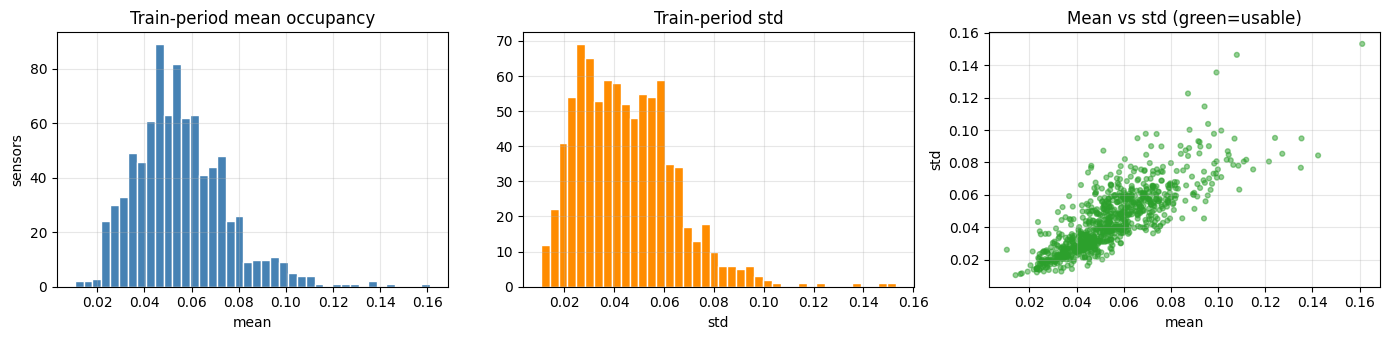

In [ ]:
TRAIN_FRAC = 0.60
VAL_FRAC = 0.20  # remaining 20% = test time (reserved in this notebook too)
N_HOURS = len(df)
train_end = int(TRAIN_FRAC * N_HOURS)
val_end = int((TRAIN_FRAC + VAL_FRAC) * N_HOURS)

train_block = df.iloc[:train_end]

sensor_stats = pd.DataFrame({
    "sensor": np.arange(df.shape[1]),
    "train_mean": train_block.mean().to_numpy(),
    "train_std": train_block.std(ddof=0).to_numpy(),
    "train_min": train_block.min().to_numpy(),
    "train_max": train_block.max().to_numpy(),
    "n_unique": train_block.nunique().to_numpy(),
    "missing": train_block.isna().sum().to_numpy(),
})
sensor_stats["range"] = sensor_stats["train_max"] - sensor_stats["train_min"]

# Hard quality gates (tune only if audit plots disagree)
MIN_STD = 1e-3
MIN_UNIQUE = 20

sensor_stats["usable"] = (
    (sensor_stats["missing"] == 0)
    & (sensor_stats["train_std"] >= MIN_STD)
    & (sensor_stats["n_unique"] >= MIN_UNIQUE)
    & (sensor_stats["train_min"] >= 0)
    & (sensor_stats["train_max"] <= 1)
)

usable = sensor_stats.loc[sensor_stats["usable"], "sensor"].to_numpy()
print(f"Usable sensors: {len(usable)} / {df.shape[1]}")
print(f"Dropped: {df.shape[1] - len(usable)}")
display(sensor_stats["usable"].value_counts().rename("count").to_frame())
display(sensor_stats.loc[~sensor_stats["usable"]].head(10))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(sensor_stats["train_mean"], bins=40, color="steelblue", edgecolor="white")
axes[0].set(title="Train-period mean occupancy", xlabel="mean", ylabel="sensors")
axes[1].hist(sensor_stats["train_std"], bins=40, color="darkorange", edgecolor="white")
axes[1].set(title="Train-period std", xlabel="std")
axes[2].scatter(
    sensor_stats["train_mean"], sensor_stats["train_std"],
    c=sensor_stats["usable"].map({True: "tab:green", False: "tab:red"}),
    s=12, alpha=0.5,
)
axes[2].set(title="Mean vs std (green=usable)", xlabel="mean", ylabel="std")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2.1 — Audit interpretation (read the plots)

- If means spread widely across sensors, a **single global scaler** would squash quiet sensors and stretch busy ones — prefer **per-sensor standardization** fit on each sensor’s training period only.
- If many sensors fail the variance / uniqueness gates, drop them; do not force a “global” model on dead loops.

## 3 — Temporal structure across sensors

**Decide:** is lookback **168** (one week) justified beyond sensor 0?

Compute Pearson autocorrelation at lags 1, 24, and 168 on the training block for a large sample of usable sensors.

,count,mean,std,min,25%,50%,75%,max
sensor,120.0,420.633333,233.044156,2.000000,223.750000,423.000000,598.500000,857.000000
acf_lag1,120.0,0.835486,0.061108,0.659908,0.803123,0.847106,0.874589,0.940824
acf_lag24,120.0,0.734390,0.084190,0.435628,0.697202,0.739499,0.790088,0.909610
acf_lag168,120.0,0.807383,0.088275,0.498382,0.774171,0.824914,0.858932,0.991717


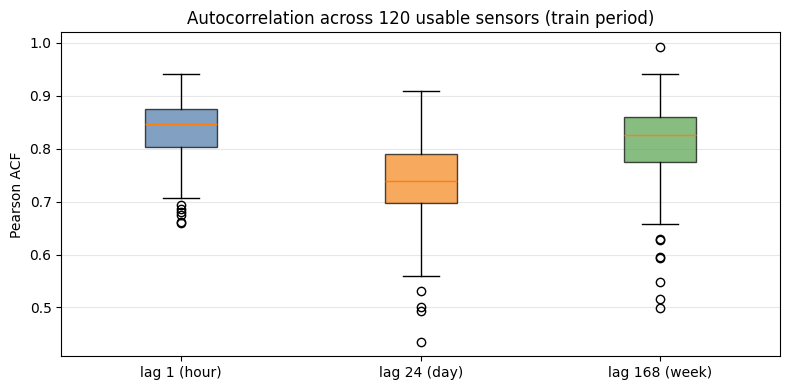

Median ACFs:
 acf_lag1      0.847106
acf_lag24     0.739499
acf_lag168    0.824914
dtype: float64

Selected LOOKBACK = 168 hours | HORIZON = 1 hour
Rule: prefer weekly lookback when median ACF@168 >= median ACF@24 across the sensor sample.


In [ ]:
RNG = np.random.default_rng(401003)
ACF_SAMPLE = min(120, len(usable))
acf_sensors = np.sort(RNG.choice(usable, size=ACF_SAMPLE, replace=False))

def acf_at_lag(x, lag):
    x = np.asarray(x, dtype=float)
    if x.std() < 1e-12:
        return np.nan
    return pd.Series(x).autocorr(lag=lag)

acf_rows = []
for s in acf_sensors:
    x = train_block[s].to_numpy()
    acf_rows.append({
        "sensor": int(s),
        "acf_lag1": acf_at_lag(x, 1),
        "acf_lag24": acf_at_lag(x, 24),
        "acf_lag168": acf_at_lag(x, 168),
    })
acf_df = pd.DataFrame(acf_rows)
display(acf_df.describe().T)

fig, ax = plt.subplots(figsize=(8, 4))
parts = ax.boxplot(
    [acf_df["acf_lag1"].dropna(), acf_df["acf_lag24"].dropna(), acf_df["acf_lag168"].dropna()],
    tick_labels=["lag 1 (hour)", "lag 24 (day)", "lag 168 (week)"],
    patch_artist=True,
)
for patch, color in zip(parts["boxes"], ["#4C78A8", "#F58518", "#54A24B"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set(title=f"Autocorrelation across {ACF_SAMPLE} usable sensors (train period)", ylabel="Pearson ACF")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

median_lags = acf_df[["acf_lag1", "acf_lag24", "acf_lag168"]].median()
print("Median ACFs:\n", median_lags)
# Decision rule used below
LOOKBACK = 168 if median_lags["acf_lag168"] >= median_lags["acf_lag24"] else 24
HORIZON = 1
print(f"\nSelected LOOKBACK = {LOOKBACK} hours | HORIZON = {HORIZON} hour")
print("Rule: prefer weekly lookback when median ACF@168 >= median ACF@24 across the sensor sample.")

## 4 — Cross-sensor similarity

**Decide:** is a shared weight set plausible, or are sensors so dissimilar that transfer is hopeless?

Pairwise correlation on a subsample of usable sensors (train period). High typical correlation → shared daily/weekly shape; very low → expect weak zero-shot transfer and rely more on pooling diversity + per-sensor scaling.

Pairwise correlations among 80 sensors:
count    3160.000000
mean        0.597230
std         0.183354
min         0.024403
10%         0.322881
25%         0.483432
50%         0.625340
75%         0.736804
90%         0.816811
max         0.987542
dtype: float64


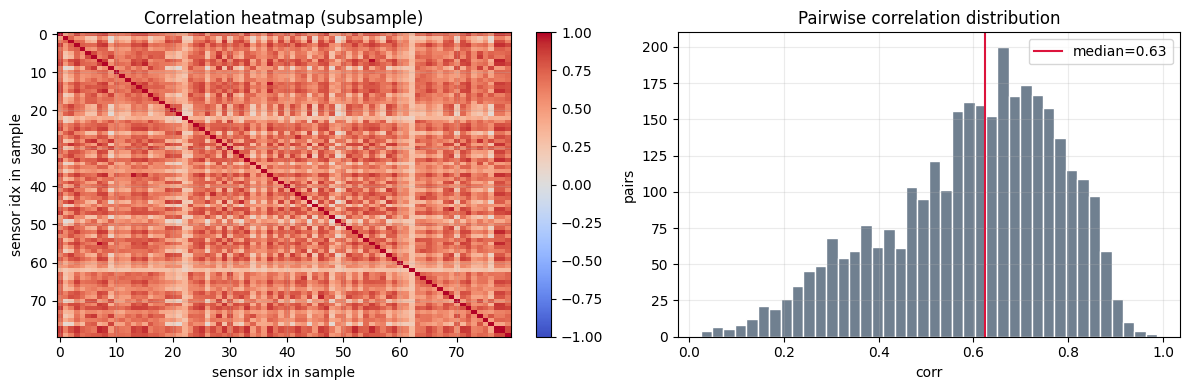

Transfer expectation: moderate-to-strong shared structure — global model is justified


In [ ]:
CORR_SAMPLE = min(80, len(usable))
corr_sensors = np.sort(RNG.choice(usable, size=CORR_SAMPLE, replace=False))
corr_mat = train_block[corr_sensors].corr()
# Upper triangle only
iu = np.triu_indices_from(corr_mat.to_numpy(), k=1)
pair_corr = corr_mat.to_numpy()[iu]

print(f"Pairwise correlations among {CORR_SAMPLE} sensors:")
print(pd.Series(pair_corr).describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im = axes[0].imshow(corr_mat, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
axes[0].set(title="Correlation heatmap (subsample)", xlabel="sensor idx in sample", ylabel="sensor idx in sample")
plt.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].hist(pair_corr, bins=40, color="slategray", edgecolor="white")
axes[1].axvline(np.median(pair_corr), color="crimson", label=f"median={np.median(pair_corr):.2f}")
axes[1].set(title="Pairwise correlation distribution", xlabel="corr", ylabel="pairs")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

median_corr = float(np.median(pair_corr))
if median_corr >= 0.4:
    transfer_expectation = "moderate-to-strong shared structure — global model is justified"
elif median_corr >= 0.2:
    transfer_expectation = "weak-to-moderate shared structure — global model may help but expect a gap vs specialists"
else:
    transfer_expectation = "weak shared structure — treat cross-sensor results cautiously"
print("Transfer expectation:", transfer_expectation)

## 5 — Design decisions (locked from analysis)

These defaults follow the audits above. Edit only if your plots disagree.

In [ ]:
# --- Modelling contract (analysis-informed) ---
# LOOKBACK / HORIZON already set in Section 3

# Per-sensor scaling: occupancy levels differ widely (Section 2).
SCALE_MODE = "per_sensor"  # do not switch to "global" without re-checking mean/std spread

# Stratify held-out sensors by train-period mean occupancy so the test pool is not only easy/quiet loops.
N_TRAIN_SENSORS = 80   # Colab-friendly; raise toward len(usable) if you have time
N_HELD_OUT_SENSORS = 25
MAX_TRAIN_WINDOWS = 80_000  # subsample pooled windows if needed
SEED = 401003

assert SCALE_MODE == "per_sensor"
assert LOOKBACK in (24, 168)
assert N_TRAIN_SENSORS + N_HELD_OUT_SENSORS <= len(usable), "Reduce N_* or relax quality gates"

print({
    "LOOKBACK": LOOKBACK,
    "HORIZON": HORIZON,
    "SCALE_MODE": SCALE_MODE,
    "N_TRAIN_SENSORS": N_TRAIN_SENSORS,
    "N_HELD_OUT_SENSORS": N_HELD_OUT_SENSORS,
    "MAX_TRAIN_WINDOWS": MAX_TRAIN_WINDOWS,
    "time_split": (train_end, val_end, N_HOURS),
    "transfer_expectation": transfer_expectation,
})

{'LOOKBACK': 168, 'HORIZON': 1, 'SCALE_MODE': 'per_sensor', 'N_TRAIN_SENSORS': 80, 'N_HELD_OUT_SENSORS': 25, 'MAX_TRAIN_WINDOWS': 80000, 'time_split': (10526, 14035, 17544), 'transfer_expectation': 'moderate-to-strong shared structure — global model is justified'}


## 6 — Stratified sensor split

Held-out sensors are drawn across occupancy quintiles (train-period mean).  
Same calendar/time indices for everyone; **no sensor in the held-out set contributes training windows**.

In [ ]:
usable_stats = sensor_stats.loc[sensor_stats["usable"]].copy()
usable_stats["occ_bin"] = pd.qcut(usable_stats["train_mean"], q=5, labels=False, duplicates="drop")

rng = np.random.default_rng(SEED)
held_out = []
train_sensors = []

for _, grp in usable_stats.groupby("occ_bin"):
    ids = grp["sensor"].to_numpy().copy()
    rng.shuffle(ids)
    # Proportional held-out take from each bin
    n_hold = max(1, int(round(N_HELD_OUT_SENSORS * len(ids) / len(usable_stats))))
    n_hold = min(n_hold, max(1, len(ids) // 5))  # leave most for train pool
    held_out.extend(ids[:n_hold].tolist())
    train_sensors.extend(ids[n_hold:].tolist())

held_out = np.array(sorted(set(held_out)), dtype=int)
train_pool = np.array(sorted(set(train_sensors) - set(held_out)), dtype=int)

# Cap train sensor count for runtime
if len(train_pool) > N_TRAIN_SENSORS:
    train_sensors = np.sort(rng.choice(train_pool, size=N_TRAIN_SENSORS, replace=False))
else:
    train_sensors = train_pool

# Cap / pad held-out to target size while keeping stratification as much as possible
if len(held_out) > N_HELD_OUT_SENSORS:
    held_out = np.sort(rng.choice(held_out, size=N_HELD_OUT_SENSORS, replace=False))
elif len(held_out) < N_HELD_OUT_SENSORS:
    extra = np.setdiff1d(train_pool, train_sensors)
    need = N_HELD_OUT_SENSORS - len(held_out)
    if len(extra) >= need:
        held_out = np.sort(np.concatenate([held_out, rng.choice(extra, size=need, replace=False)]))

# Ensure disjoint
assert len(np.intersect1d(train_sensors, held_out)) == 0

split_summary = pd.DataFrame({
    "role": ["train_sensors", "held_out_sensors"],
    "count": [len(train_sensors), len(held_out)],
    "mean_of_means": [
        sensor_stats.set_index("sensor").loc[train_sensors, "train_mean"].mean(),
        sensor_stats.set_index("sensor").loc[held_out, "train_mean"].mean(),
    ],
    "mean_of_stds": [
        sensor_stats.set_index("sensor").loc[train_sensors, "train_std"].mean(),
        sensor_stats.set_index("sensor").loc[held_out, "train_std"].mean(),
    ],
})
display(split_summary)
print("Held-out sensors:", held_out.tolist())
print("Train sensors (first 20):", train_sensors[:20].tolist(), "…")


,role,count,mean_of_means,mean_of_stds
0,train_sensors,80,0.055202,0.046893
1,held_out_sensors,25,0.054075,0.039150


Held-out sensors: [43, 57, 94, 174, 175, 207, 214, 219, 298, 313, 457, 561, 606, 618, 650, 686, 691, 694, 739, 741, 748, 780, 781, 788, 839]
Train sensors (first 20): [2, 6, 24, 27, 63, 74, 102, 134, 144, 145, 146, 155, 167, 195, 200, 204, 206, 210, 233, 238] …


## 7 — Per-sensor scaling, chronological windows, pooling

For each sensor \(s\):

1. Fit mean/std on **train hours only** for that sensor  
2. Build supervised windows inside each time block (train / val / test)  
3. Pool windows across **train sensors** for fitting  
4. Score on **held-out sensors** (validation hours for model selection; test hours reserved)

Windows never cross time-block boundaries. Targets stay in original occupancy units for MAE/RMSE after inverse transform.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def fit_sensor_scaler(series_train):
    mu = float(np.mean(series_train))
    sigma = float(np.std(series_train))
    if sigma < 1e-8:
        sigma = 1.0
    return mu, sigma

def transform(x, mu, sigma):
    return (x - mu) / sigma

def inverse_transform(x, mu, sigma):
    return x * sigma + mu

def make_windows(values, lookback):
    values = np.asarray(values, dtype=np.float32)
    n = len(values) - lookback
    if n <= 0:
        return np.empty((0, lookback), np.float32), np.empty((0,), np.float32)
    shape = (n, lookback)
    strides = (values.strides[0], values.strides[0])
    X = np.lib.stride_tricks.as_strided(values, shape=shape, strides=strides).copy()
    y = values[lookback:].copy()
    return X, y

def build_sensor_windows(sensor_id, lookback=LOOKBACK):
    raw = df[sensor_id].to_numpy(dtype=np.float64)
    tr = raw[:train_end]
    va = raw[train_end:val_end]
    te = raw[val_end:]
    mu, sigma = fit_sensor_scaler(tr)
    tr_s = transform(tr, mu, sigma)
    va_s = transform(va, mu, sigma)
    te_s = transform(te, mu, sigma)
    Xtr, ytr = make_windows(tr_s, lookback)
    Xva, yva = make_windows(va_s, lookback)
    Xte, yte = make_windows(te_s, lookback)
    ytr_raw = tr[lookback:lookback + len(ytr)]
    yva_raw = va[lookback:lookback + len(yva)]
    yte_raw = te[lookback:lookback + len(yte)]
    return {
        "sensor": sensor_id,
        "mu": mu,
        "sigma": sigma,
        "X_train": Xtr, "y_train": ytr, "y_train_raw": ytr_raw.astype(np.float32),
        "X_val": Xva, "y_val": yva, "y_val_raw": yva_raw.astype(np.float32),
        "X_test": Xte, "y_test": yte, "y_test_raw": yte_raw.astype(np.float32),
    }

print("Building windows for train sensors …")
train_packs = [build_sensor_windows(int(s)) for s in train_sensors]
print("Building windows for held-out sensors …")
held_packs = [build_sensor_windows(int(s)) for s in held_out]

X_train = np.concatenate([p["X_train"] for p in train_packs], axis=0)
y_train = np.concatenate([p["y_train"] for p in train_packs], axis=0)
X_val_train_sensors = np.concatenate([p["X_val"] for p in train_packs], axis=0)
y_val_train_sensors = np.concatenate([p["y_val"] for p in train_packs], axis=0)
y_val_train_sensors_raw = np.concatenate([p["y_val_raw"] for p in train_packs], axis=0)

rng = np.random.default_rng(SEED)
if len(X_train) > MAX_TRAIN_WINDOWS:
    idx = rng.choice(len(X_train), size=MAX_TRAIN_WINDOWS, replace=False)
    X_train, y_train = X_train[idx], y_train[idx]
    print(f"Subsampled training windows to {MAX_TRAIN_WINDOWS}")

X_val_held = np.concatenate([p["X_val"] for p in held_packs], axis=0)
y_val_held = np.concatenate([p["y_val"] for p in held_packs], axis=0)
y_val_held_raw = np.concatenate([p["y_val_raw"] for p in held_packs], axis=0)

shapes = pd.DataFrame([
    {"set": "train (pooled train sensors)", "X": X_train.shape, "y": y_train.shape},
    {"set": "val (train sensors)", "X": X_val_train_sensors.shape, "y": y_val_train_sensors.shape},
    {"set": "val (held-out sensors)", "X": X_val_held.shape, "y": y_val_held.shape},
])
display(shapes)
print(f"Lookback={LOOKBACK} → MLP/CNN input length {LOOKBACK}")


Building windows for train sensors …
Building windows for held-out sensors …
Subsampled training windows to 80000


,set,X,y
0,train (pooled train sensors),"(80000, 168)","(80000,)"
1,val (train sensors),"(267280, 168)","(267280,)"
2,val (held-out sensors),"(83525, 168)","(83525,)"


Lookback=168 → MLP/CNN input length 168


## 8 — Baselines on held-out sensors

Three copies of the past, scored on **held-out sensors / validation hours**. A global network has to beat these to show transfer.

- **Persistence:** repeat the last hour (lag 1).
- **Hourly seasonal naive:** repeat the same clock hour yesterday (lag 24). This is the daily cycle from the autocorrelation plot, not another name for persistence.
- **Weekly seasonal naive:** repeat the same hour last week (lag 168). If the lookback is only 24 hours, this uses the oldest hour in the window.

In [ ]:
def seasonal_naive_pred(packs, lag, split="val"):
    """Repeat the value `lag` hours before the target. Lag 1 is persistence."""
    rows = []
    for p in packs:
        Xb = p[f"X_{split}"]
        y_raw = p[f"y_{split}_raw"]
        if len(Xb) == 0:
            continue
        pred_scaled = Xb[:, -lag] if lag <= Xb.shape[1] else Xb[:, 0]
        pred = inverse_transform(pred_scaled, p["mu"], p["sigma"])
        rows.append((y_raw, pred))
    y = np.concatenate([r[0] for r in rows])
    pred = np.concatenate([r[1] for r in rows])
    return y, pred

def metrics(y, pred, name):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y, pred),
        "RMSE": mean_squared_error(y, pred) ** 0.5,
    }

y_h, pred_p = seasonal_naive_pred(held_packs, 1, "val")
_, pred_hour = seasonal_naive_pred(held_packs, 24, "val")
_, pred_w = seasonal_naive_pred(held_packs, 168, "val")

baseline_table = pd.DataFrame([
    metrics(y_h, pred_p, "Persistence (held-out val)"),
    metrics(y_h, pred_hour, "Hourly seasonal naive (held-out val)"),
    metrics(y_h, pred_w, "Weekly seasonal naive (held-out val)"),
])
display(baseline_table)
best_baseline_rmse = baseline_table["RMSE"].min()
print(f"Best baseline RMSE on held-out val: {best_baseline_rmse:.5f}")

,Model,MAE,RMSE
0,Persistence (held-out val),0.012639,0.024846
1,Weekly seasonal naive (held-out val),0.010564,0.027648


Best baseline RMSE on held-out val: 0.02485


## 9 — Global MLP

One network shared across train sensors. Input: flattened length-`LOOKBACK` history (per-sensor standardized).  
Early stopping monitors **train-sensor validation** loss (tuning signal). Transfer is judged on **held-out sensors**. Width, dropout, and learning rate here are the default cell of the Section 11 grid, not the searched winner.

In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Conv1D, MaxPooling1D, Flatten, Dropout, LSTM
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__)

def score_packs(model, packs, split="val", cnn=False):
    rows_y, rows_p = [], []
    for p in packs:
        Xb = p[f"X_{split}"]
        if len(Xb) == 0:
            continue
        Xin = Xb[..., None] if cnn else Xb
        pred_scaled = model.predict(Xin, verbose=0).ravel()
        pred = inverse_transform(pred_scaled, p["mu"], p["sigma"])
        rows_y.append(p[f"y_{split}_raw"])
        rows_p.append(pred.astype(np.float32))
    y = np.concatenate(rows_y)
    pred = np.concatenate(rows_p)
    return metrics(y, pred, "tmp"), y, pred

EPOCHS = 40
PATIENCE = 5
BATCH = 64
LR = 1e-3

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
mlp = Sequential([
    Input(shape=(LOOKBACK,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1),
])
mlp.compile(optimizer=Adam(LR), loss="mse")
mlp.summary()

rng = np.random.default_rng(SEED)
if len(X_val_train_sensors) > 30_000:
    vidx = rng.choice(len(X_val_train_sensors), size=30_000, replace=False)
    X_es, y_es = X_val_train_sensors[vidx], y_val_train_sensors[vidx]
else:
    X_es, y_es = X_val_train_sensors, y_val_train_sensors

t0 = perf_counter()
mlp_hist = mlp.fit(
    X_train, y_train,
    validation_data=(X_es, y_es),
    epochs=EPOCHS,
    batch_size=BATCH,
    shuffle=True,  # cross-sensor pool: shuffle OK within train-time windows
    callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
    verbose=1,
)
mlp_time = perf_counter() - t0
mlp_default_weights = mlp.get_weights()
print(f"MLP training time: {mlp_time:.1f}s | epochs run: {len(mlp_hist.history['loss'])}")

mlp_held_metrics, _, _ = score_packs(mlp, held_packs, "val", cnn=False)
mlp_held_metrics["Model"] = "Global MLP (held-out val)"
mlp_held_metrics["Params"] = mlp.count_params()
mlp_held_metrics["Train seconds"] = mlp_time
display(pd.DataFrame([mlp_held_metrics]))

TensorFlow 2.21.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        10,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,929 (50.50 KB)

 Trainable params: 12,929 (50.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.1991 - val_loss: 0.1773
Epoch 2/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1535 - val_loss: 0.1701
Epoch 3/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1434 - val_loss: 0.1613
Epoch 4/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.1378 - val_loss: 0.1584
Epoch 5/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.1336 - val_loss: 0.1561
Epoch 6/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1302 - val_loss: 0.1545
Epoch 7/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1269 - val_loss: 0.1563
Epoch 8/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.1243 - val_loss: 0.1522
Epoch 9/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1217 - val_loss: 0.1514
Epoch 10/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1191 - val_loss: 0.1517
Epoch 11/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1168 - val_loss: 0.1520
Epoch 12/40
1250/1250 ━━━━━━━━

,Model,MAE,RMSE,Params,Train seconds
0,Global MLP (held-out val),0.008546,0.017666,12929,61.908806


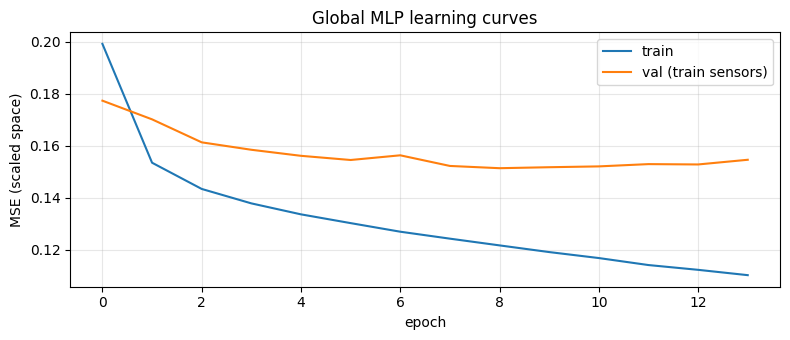

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(mlp_hist.history["loss"], label="train")
ax.plot(mlp_hist.history["val_loss"], label="val (train sensors)")
ax.set(title="Global MLP learning curves", xlabel="epoch", ylabel="MSE (scaled space)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 10 — Global CNN

Same pooled windows, reshaped to `(lookback, 1)`. Conv filters should pick up local rush-hour shapes that recur across sensors after per-sensor scaling. Filter counts, kernel sizes, and learning rate here are the default cell of the Section 11 grid, not the searched winner.

In [ ]:
X_train_cnn = X_train[..., None]
X_es_cnn = X_es[..., None]

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
cnn = Sequential([
    Input(shape=(LOOKBACK, 1)),
    Conv1D(16, kernel_size=7, activation="relu", padding="same"),
    MaxPooling1D(2),
    Conv1D(32, kernel_size=5, activation="relu", padding="same"),
    MaxPooling1D(2),
    Flatten(),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1),
])
cnn.compile(optimizer=Adam(LR), loss="mse")
cnn.summary()

t0 = perf_counter()
cnn_hist = cnn.fit(
    X_train_cnn, y_train,
    validation_data=(X_es_cnn, y_es),
    epochs=EPOCHS,
    batch_size=BATCH,
    shuffle=True,
    callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
    verbose=1,
)
cnn_time = perf_counter() - t0
cnn_default_weights = cnn.get_weights()
print(f"CNN training time: {cnn_time:.1f}s | epochs run: {len(cnn_hist.history['loss'])}")

cnn_held_metrics, _, _ = score_packs(cnn, held_packs, "val", cnn=True)
cnn_held_metrics["Model"] = "Global CNN (held-out val)"
cnn_held_metrics["Params"] = cnn.count_params()
cnn_held_metrics["Train seconds"] = cnn_time
display(pd.DataFrame([cnn_held_metrics]))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 168, 16)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 84, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 84, 32)         │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 42, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1344)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        43,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 45,793 (178.88 KB)

 Trainable params: 45,793 (178.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - loss: 0.2174 - val_loss: 0.1639
Epoch 2/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step - loss: 0.1702 - val_loss: 0.1537
Epoch 3/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.1635 - val_loss: 0.1502
Epoch 4/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1585 - val_loss: 0.1498
Epoch 5/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.1571 - val_loss: 0.1510
Epoch 6/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1543 - val_loss: 0.1495
Epoch 7/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1501 - val_loss: 0.1498
Epoch 8/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.1498 - val_loss: 0.1522
Epoch 9/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1475 - val_loss: 0.1536
Epoch 10/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.1443 - val_loss: 0.1545
Epoch 11/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.1431 - val_loss: 0.1526
CNN training time: 68.2s | e

,Model,MAE,RMSE,Params,Train seconds
0,Global CNN (held-out val),0.008282,0.017472,45793,68.165998


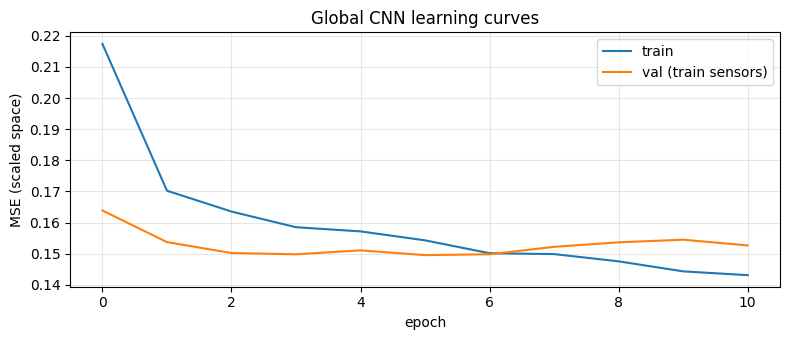

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(cnn_hist.history["loss"], label="train")
ax.plot(cnn_hist.history["val_loss"], label="val (train sensors)")
ax.set(title="Global CNN learning curves", xlabel="epoch", ylabel="MSE (scaled space)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 11 — MLP and CNN grid search

The default MLP and CNN each use one setting. This section searches a full grid around those settings. The screening budget matches the TCN search in Section 16: at most 40,000 pooled windows, 15 epochs, and patience 3.

| Model | Parameter | Values | Default in the grid |
|---|---|---|---|
| MLP | Hidden widths | (32,) one layer, (64, 32) | (64, 32) |
| MLP | Dropout after the hidden layers | 0.0, 0.2 | 0.0 |
| MLP | Learning rate | 0.01, 0.001 | 0.001 |
| CNN | Conv filters | (8, 16), (16, 32) | (16, 32) |
| CNN | Kernel sizes | (7, 5), (3, 3) | (7, 5) |
| CNN | Learning rate | 0.001, 0.0005 | 0.001 |

That is **8 MLP** and **8 CNN** screening fits. Batch size 64, MSE, and seed `401003` stay fixed. The CNN dense layer stays 32 units and its dropout stays 0.2, so the Section 10 network is one cell of the CNN grid. The Section 9 network is one cell of the MLP grid.

The values come from the univariate sensor-0 searches, not from a neighborhood of the larger defaults. Matt's MLP winner was one hidden layer of 32 units and learning rate 0.01, with lookback 168. Lookback is not searched again; Section 5 already fixed it at 168. Janik's CNN winner was 8 filters, kernel size 7, dropout 0.2, batch size 64, and learning rate 0.001. Nimer's was 32 filters, kernel size 5, and learning rate 0.0005. Dropout 0.2 and batch size 64 stay fixed because they were the selected CNN settings. This network has two convolutions, so it cannot copy those one-convolution layouts; filter count, kernel size, and learning rate are the knobs moved toward the earlier winners.

The winner is the lowest **held-out validation RMSE**, the same objective as the TCN search. Exact ties prefer fewer parameters, then the earlier trial. That winner is retrained on all pooled training windows with the 40-epoch cap and patience 5 used by the default models. Early stopping during both phases still watches train-sensor validation loss. The test block is not used.


In [ ]:
from itertools import product

# Same screening budget as the TCN search in Section 16.
GRID_EPOCHS = 15
GRID_PATIENCE = 3
GRID_MAX_TRAIN = 40_000

def expand_grid(space):
    keys = list(space)
    return [dict(zip(keys, values)) for values in product(*(space[key] for key in keys))]

rng = np.random.default_rng(SEED)
if len(X_train) > GRID_MAX_TRAIN:
    gidx = rng.choice(len(X_train), size=GRID_MAX_TRAIN, replace=False)
    X_grid_flat, y_grid_flat = X_train[gidx], y_train[gidx]
else:
    X_grid_flat, y_grid_flat = X_train, y_train
X_grid_seq = X_grid_flat[..., None]

mlp_space = {
    "hidden": [(32, 0), (64, 32)],
    "dropout": [0.0, 0.2],
    "learning_rate": [1e-2, 1e-3],
}
cnn_space = {
    "filters": [(8, 16), (16, 32)],
    "kernels": [(7, 5), (3, 3)],
    "learning_rate": [1e-3, 5e-4],
}

def build_mlp_from(config):
    hidden_1, hidden_2 = config["hidden"]
    layers = [
        Input(shape=(LOOKBACK,)),
        Dense(hidden_1, activation="relu"),
    ]
    if hidden_2:
        layers.append(Dense(hidden_2, activation="relu"))
    if config["dropout"] > 0:
        layers.append(Dropout(config["dropout"]))
    layers.append(Dense(1))
    model = Sequential(layers)
    model.compile(optimizer=Adam(config["learning_rate"]), loss="mse")
    return model

def build_cnn_from(config):
    filters_1, filters_2 = config["filters"]
    kernel_1, kernel_2 = config["kernels"]
    model = Sequential([
        Input(shape=(LOOKBACK, 1)),
        Conv1D(filters_1, kernel_size=kernel_1, activation="relu", padding="same"),
        MaxPooling1D(2),
        Conv1D(filters_2, kernel_size=kernel_2, activation="relu", padding="same"),
        MaxPooling1D(2),
        Flatten(),
        Dense(32, activation="relu"),
        Dropout(0.2),
        Dense(1),
    ])
    model.compile(optimizer=Adam(config["learning_rate"]), loss="mse")
    return model

def flatten_config(config):
    flat = {}
    for key, value in config.items():
        if isinstance(value, tuple):
            for index, part in enumerate(value, start=1):
                flat[f"{key}_{index}"] = part
        else:
            flat[key] = value
    return flat

def run_grid(name, configs, builder, x_tr, y_tr, x_va, y_va, sequence):
    """Screen on the shared subset. Selection score is held-out RMSE, matching the TCN."""
    rows = []
    for trial, config in enumerate(configs, start=1):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = builder(config)
        start = perf_counter()
        history = model.fit(
            x_tr, y_tr,
            validation_data=(x_va, y_va),
            epochs=GRID_EPOCHS,
            batch_size=BATCH,
            shuffle=True,
            callbacks=[EarlyStopping(monitor="val_loss", patience=GRID_PATIENCE, restore_best_weights=True)],
            verbose=0,
        )
        seconds = perf_counter() - start
        held, _, _ = score_packs(model, held_packs, "val", cnn=sequence)
        params = int(model.count_params())
        rows.append({
            "Trial": trial,
            **flatten_config(config),
            "Train-sensor val loss": float(np.min(history.history["val_loss"])),
            "Held-out RMSE": held["RMSE"],
            "Held-out MAE": held["MAE"],
            "Best epoch": int(np.argmin(history.history["val_loss"])) + 1,
            "Epochs trained": len(history.history["loss"]),
            "Params": params,
            "Screen seconds": seconds,
        })
        print(f"{name} {trial}/{len(configs)}: held-out RMSE={held['RMSE']:.5f}, params={params}, {seconds:.1f}s")
        del model
    return (
        pd.DataFrame(rows)
        .sort_values(["Held-out RMSE", "Params", "Trial"])
        .reset_index(drop=True)
    )

def retrain_winner(builder, config, x_tr, y_tr, x_va, y_va, sequence, label):
    """Full pooled training budget, same early-stopping split as the default models."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = builder(config)
    start = perf_counter()
    model.fit(
        x_tr, y_tr,
        validation_data=(x_va, y_va),
        epochs=EPOCHS,
        batch_size=BATCH,
        shuffle=True,
        callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
        verbose=0,
    )
    seconds = perf_counter() - start
    weights = model.get_weights()
    held, _, _ = score_packs(model, held_packs, "val", cnn=sequence)
    held["Model"] = label
    held["Params"] = int(model.count_params())
    held["Train seconds"] = seconds
    return weights, held

mlp_configs = expand_grid(mlp_space)
cnn_configs = expand_grid(cnn_space)
print(
    f"Search budget: {len(mlp_configs)} MLP + {len(cnn_configs)} CNN "
    f"on {len(X_grid_flat)} windows, {GRID_EPOCHS} epochs"
)

screen_start = perf_counter()
mlp_grid_results = run_grid(
    "MLP", mlp_configs, build_mlp_from, X_grid_flat, y_grid_flat, X_es, y_es, False
)
cnn_grid_results = run_grid(
    "CNN", cnn_configs, build_cnn_from, X_grid_seq, y_grid_flat, X_es_cnn, y_es, True
)
screen_seconds = perf_counter() - screen_start

best_mlp_config = mlp_configs[int(mlp_grid_results.iloc[0]["Trial"]) - 1]
best_cnn_config = cnn_configs[int(cnn_grid_results.iloc[0]["Trial"]) - 1]
mlp_weights, mlp_tuned_metrics = retrain_winner(
    build_mlp_from, best_mlp_config, X_train, y_train, X_es, y_es, False,
    "Tuned global MLP (held-out val)",
)
cnn_weights, cnn_tuned_metrics = retrain_winner(
    build_cnn_from, best_cnn_config, X_train_cnn, y_train, X_es_cnn, y_es, True,
    "Tuned global CNN (held-out val)",
)

print("\nMLP grid (selected row is first):")
display(mlp_grid_results)
print("Selected MLP:", best_mlp_config)
print("\nCNN grid (selected row is first):")
display(cnn_grid_results)
print("Selected CNN:", best_cnn_config)
print(f"Screening wall time: {screen_seconds:.1f}s. Tuned-row times below are the full retrains, not the search.")
display(pd.DataFrame([mlp_tuned_metrics, cnn_tuned_metrics]))


## 12 — Best MLP and CNN against the naive baselines

Stage 1 ends here. The question is whether either network, after the Section 11 search, beats persistence and the two seasonal naive copies on sensors it never trained on.

The tuned rows are the Section 11 winners after they are retrained on all pooled training windows. The default rows are the Section 9 and 10 starting points. LSTM and TCN are not in this table.

,Model,MAE,RMSE,Params,Train seconds,RMSE improvement vs best baseline (%)
0,Global CNN (held-out val),0.008282,0.017472,45793,68.165998,29.677706
1,Global MLP (held-out val),0.008546,0.017666,12929,61.908806,28.898110
2,Persistence (held-out val),0.012639,0.024846,0,0.000000,0.000000
3,Weekly seasonal naive (held-out val),0.010564,0.027648,0,0.000000,-11.278115


,sensor,Global CNN RMSE,Persistence RMSE,Weekly naive RMSE,train_mean,beats_best_baseline
12,606,0.005351,0.011877,0.007790,0.031188,True
3,174,0.005753,0.010312,0.013990,0.025547,True
2,94,0.007220,0.013411,0.012685,0.021368,True
18,739,0.008555,0.015794,0.013777,0.044397,True
17,694,0.008851,0.012742,0.013905,0.036105,True
6,214,0.009232,0.011670,0.014226,0.045390,True
4,175,0.011633,0.020342,0.018770,0.043694,True
13,618,0.011769,0.018710,0.016818,0.042008,True
22,781,0.011824,0.016964,0.018942,0.060058,True
1,57,0.012467,0.020125,0.016804,0.039575,True


Global CNN beats best baseline on 100% of held-out sensors


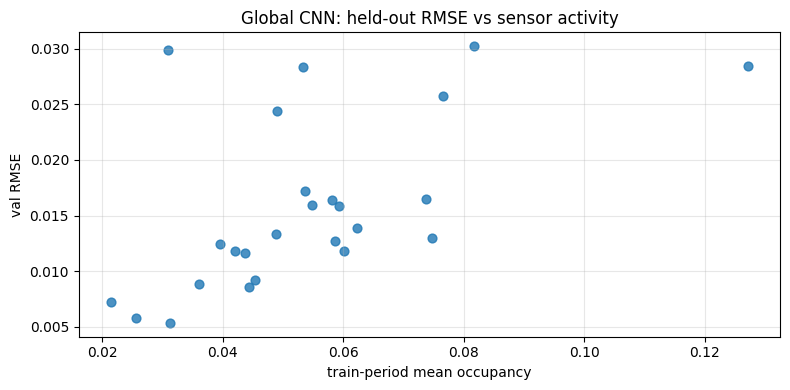

In [ ]:
def restore_model(builder, config, weights):
    model = builder(config)
    model.set_weights(weights)
    return model

# Screening calls clear_session between trials. Reload every model this plot may call.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
mlp = restore_model(build_mlp_from, {"hidden": (64, 32), "dropout": 0.0, "learning_rate": LR}, mlp_default_weights)
cnn = restore_model(build_cnn_from, {"filters": (16, 32), "kernels": (7, 5), "learning_rate": LR}, cnn_default_weights)
best_mlp = restore_model(build_mlp_from, best_mlp_config, mlp_weights)
best_cnn = restore_model(build_cnn_from, best_cnn_config, cnn_weights)

baseline_rows = [
    {**row, "Params": 0, "Train seconds": 0.0}
    for row in baseline_table.to_dict(orient="records")
]
comparison = pd.DataFrame([
    *baseline_rows,
    mlp_held_metrics,
    cnn_held_metrics,
    mlp_tuned_metrics,
    cnn_tuned_metrics,
])
comparison["RMSE improvement vs best baseline (%)"] = (
    100 * (best_baseline_rmse - comparison["RMSE"]) / best_baseline_rmse
)
comparison = comparison.sort_values("RMSE").reset_index(drop=True)
display(comparison)

candidates = [
    (mlp, False, "Global MLP", mlp_held_metrics["RMSE"]),
    (cnn, True, "Global CNN", cnn_held_metrics["RMSE"]),
    (best_mlp, False, "Tuned MLP", mlp_tuned_metrics["RMSE"]),
    (best_cnn, True, "Tuned CNN", cnn_tuned_metrics["RMSE"]),
]
cand_model, needs_channel, cand_label, _ = min(candidates, key=lambda item: item[3])

per_sensor_rows = []
for p in held_packs:
    Xb = p["X_val"]
    if len(Xb) == 0:
        continue
    Xin = Xb[..., None] if needs_channel else Xb
    pred = inverse_transform(cand_model.predict(Xin, verbose=0).ravel(), p["mu"], p["sigma"])
    pers = inverse_transform(Xb[:, -1], p["mu"], p["sigma"])
    hourly = inverse_transform(Xb[:, -24] if LOOKBACK >= 24 else Xb[:, 0], p["mu"], p["sigma"])
    weekly = inverse_transform(Xb[:, -168] if LOOKBACK >= 168 else Xb[:, 0], p["mu"], p["sigma"])
    y = p["y_val_raw"]
    per_sensor_rows.append({
        "sensor": p["sensor"],
        f"{cand_label} RMSE": mean_squared_error(y, pred) ** 0.5,
        "Persistence RMSE": mean_squared_error(y, pers) ** 0.5,
        "Hourly naive RMSE": mean_squared_error(y, hourly) ** 0.5,
        "Weekly naive RMSE": mean_squared_error(y, weekly) ** 0.5,
        "train_mean": float(sensor_stats.set_index("sensor").loc[p["sensor"], "train_mean"]),
    })
per_sensor = pd.DataFrame(per_sensor_rows)
baseline_cols = ["Persistence RMSE", "Hourly naive RMSE", "Weekly naive RMSE"]
per_sensor["beats_best_baseline"] = per_sensor[f"{cand_label} RMSE"] < per_sensor[baseline_cols].min(axis=1)
display(per_sensor.sort_values(f"{cand_label} RMSE").head(10))
print(f"{cand_label} beats best baseline on {per_sensor['beats_best_baseline'].mean():.0%} of held-out sensors")

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(per_sensor["train_mean"], per_sensor[f"{cand_label} RMSE"], s=40, alpha=0.8)
ax.set(title=f"{cand_label}: held-out RMSE vs sensor activity", xlabel="train-period mean occupancy", ylabel="val RMSE")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 13 — Optional diagnostic: specialist vs global transfer

Train a **sensor-0-only** MLP on the same protocol, then score it on held-out sensors.  
If the global model wins by a clear margin, pooling many sensors helped transfer.  
If not, cross-sensor heterogeneity may dominate (revisit scaling, lookback, or sensor clustering).

In [ ]:
specialist_id = 0 if 0 in set(usable.tolist()) else int(train_sensors[0])
spec = build_sensor_windows(specialist_id)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
spec_mlp = Sequential([
    Input(shape=(LOOKBACK,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1),
])
spec_mlp.compile(optimizer=Adam(LR), loss="mse")
spec_mlp.fit(
    spec["X_train"], spec["y_train"],
    validation_data=(spec["X_val"], spec["y_val"]),
    epochs=EPOCHS, batch_size=BATCH, shuffle=False,
    callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
    verbose=0,
)
spec_metrics, _, _ = score_packs(spec_mlp, held_packs, "val", cnn=False)
spec_metrics["Model"] = f"Specialist MLP on sensor {specialist_id} → held-out"
display(pd.DataFrame([
    spec_metrics,
    mlp_held_metrics,
    cnn_held_metrics,
    mlp_tuned_metrics,
    cnn_tuned_metrics,
]).sort_values("RMSE"))

,Model,MAE,RMSE,Params,Train seconds
2,Global CNN (held-out val),0.008282,0.017472,45793.0,68.165998
1,Global MLP (held-out val),0.008546,0.017666,12929.0,61.908806
0,Specialist MLP on sensor 0 → held-out,0.017509,0.031121,NaN,NaN


# Stage 2 — RNN, LSTM and TCN

Stage 1 chose an MLP and a CNN by comparing them with the naive baselines. This stage trains an RNN, LSTM, and a causal TCN on the same windows, searches their settings on held-out validation RMSE, and then puts those models next to the Stage 1 winners.


## 14 — Global RNN

Train a **vanilla RNN** on the same pooled training windows as the MLP and CNN. The model uses a `SimpleRNN` layer followed by a `Dense(1)` output to predict next-hour occupancy.

**Training and validation.** The default RNN uses 64 hidden units, Adam with learning rate 0.001, and MSE loss. Early stopping monitors train-sensor validation loss. Performance is measured on the 25 held-out sensors using MAE and RMSE.

**Grid search.** Search 8 configurations using:

| Parameter | Values |
|---|---|
| Hidden units | 32, 64 |
| Learning rate | 0.001, 0.0005 |
| Dropout | 0.0, 0.2 |

The winner is selected using the lowest **held-out validation RMSE**. The test block is not used.




### 14.1 — RNN Setup and First Model
The vanilla recurrent cell updates its hidden state at each hour using the present reading and the previous hidden state. The `SimpleRNN` layer returns its final hidden representation, and `Dense(1)` predicts the next-hour standardized occupancy. Input format: **(samples, LOOKBACK, 1)**.

In [ ]:
from tensorflow.keras.layers import SimpleRNN
import json

assert HORIZON == 1,
assert X_train.ndim == 2 and X_train.shape[1] == LOOKBACK
assert X_es.ndim == 2 and X_es.shape[1] == LOOKBACK
assert len(np.intersect1d(train_sensors, held_out)) == 0

X_train_rnn = X_train[..., np.newaxis].astype(np.float32, copy=False)
X_es_rnn = X_es[..., np.newaxis].astype(np.float32, copy=False)
print("RNN train shape:", X_train_rnn.shape)
print("RNN early-stopping validation shape:", X_es_rnn.shape)

def build_global_rnn(units=64, learning_rate=1e-3, dropout=0.0):
    model = Sequential([
        Input(shape=(LOOKBACK, 1)),
        SimpleRNN(units, dropout=dropout),
        Dense(1),
    ], name=f"global_rnn_u{units}_lr{learning_rate:g}_drop{dropout:g}")
    model.compile(optimizer=Adam(learning_rate=learning_rate, clipnorm=1.0), loss="mse")
    return model

tf.keras.utils.set_random_seed(SEED)
rnn = build_global_rnn(units=64, learning_rate=LR)
rnn.summary()

RNN train shape: (80000, 168, 1)
RNN early-stopping validation shape: (30000, 168, 1)


Model: "global_rnn_u64_lr0.001_drop0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289 (16.75 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 0 (0.00 B)

#### 14.1.1 — Train, validate, and plot learning curves

Training loss is computed from pooled **training-sensor** windows. Validation loss comes from the same sensors in a later time interval. `restore_best_weights=True` reloads the checkpoint with the lowest early-stopping validation loss.

Epoch 1/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - loss: 0.1992 - val_loss: 0.1890
Epoch 2/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - loss: 0.1817 - val_loss: 0.1859
Epoch 3/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - loss: 0.1765 - val_loss: 0.1818
Epoch 4/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - loss: 0.1734 - val_loss: 0.1778
Epoch 5/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - loss: 0.1712 - val_loss: 0.1769
Epoch 6/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - loss: 0.1689 - val_loss: 0.1781
Epoch 7/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - loss: 0.1674 - val_loss: 0.1776
Epoch 8/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - loss: 0.1658 - val_loss: 0.1778
Epoch 9/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - loss: 0.1660 - val_loss: 0.1760
Epoch 10/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - loss: 0.1643 - val_loss: 0.1747
Epoch 11/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 17s 13ms/step - loss: 0.1641 - val_loss: 0.1725
Epoch 12

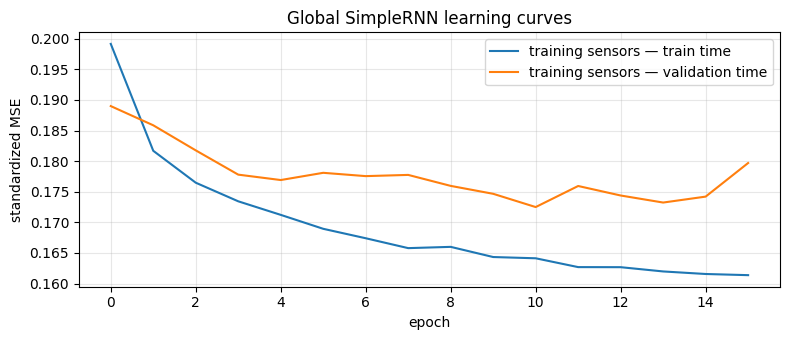

In [ ]:
t0 = perf_counter()
rnn_hist = rnn.fit(
    X_train_rnn, y_train,
    validation_data=(X_es_rnn, y_es),
    epochs=EPOCHS,
    batch_size=BATCH,
    shuffle=True,  # allowed within the training-time pool of independent windows
    callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE,
                             restore_best_weights=True)],
    verbose=1,
)
rnn_time = perf_counter() - t0
print(f"Initial RNN: {len(rnn_hist.history['loss'])} epochs, {rnn_time:.1f} seconds")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(rnn_hist.history["loss"], label="training sensors — train time")
ax.plot(rnn_hist.history["val_loss"], label="training sensors — validation time")
ax.set(title="Global SimpleRNN learning curves", xlabel="epoch", ylabel="standardized MSE")
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()

#### 14.1.2 — Predictions and initial assessment on held-out sensors

The previously defined `score_packs(..., cnn=True)` helper reshapes `(N, LOOKBACK)` into `(N, LOOKBACK, 1)` for **any sequential model**, including the RNN. It inverse-transforms predictions with each held-out sensor's own training-period mean and standard deviation, then calculates MAE/RMSE in **occupancy units**. We also time inference on the full held-out validation set (timing will be machine-dependent).

,Model,MAE,RMSE,Params,Train seconds,Inference seconds,Inference ms/window
0,Global RNN (held-out val),0.009284,0.018797,4289,281.073107,11.926365,0.142788


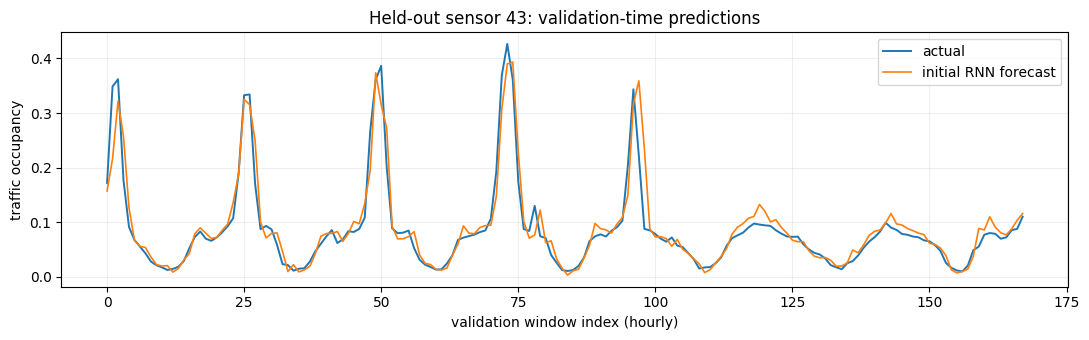

In [ ]:
t0 = perf_counter()
rnn_held_metrics, rnn_y_val, rnn_y_pred = score_packs(rnn, held_packs, split="val", cnn=True)
rnn_infer_seconds = perf_counter() - t0
rnn_held_metrics.update({
    "Model": "Global RNN (held-out val)",
    "Params": rnn.count_params(),
    "Train seconds": rnn_time,
    "Inference seconds": rnn_infer_seconds,
    "Inference ms/window": 1e3 * rnn_infer_seconds / len(rnn_y_val),
})
display(pd.DataFrame([rnn_held_metrics]))

# One held-out sensor example: temporally ordered actual vs predictions.
example_pack = held_packs[0]
example_X = example_pack["X_val"][..., None]
example_pred_scaled = rnn.predict(example_X, verbose=0).ravel()
example_pred = inverse_transform(example_pred_scaled, example_pack["mu"], example_pack["sigma"])
example_actual = example_pack["y_val_raw"]
show_n = min(168, len(example_actual))
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(example_actual[:show_n], label="actual", lw=1.4)
ax.plot(example_pred[:show_n], label="initial RNN forecast", lw=1.2)
ax.set(title=f"Held-out sensor {example_pack['sensor']}: validation-time predictions",
       xlabel="validation window index (hourly)", ylabel="traffic occupancy")
ax.grid(alpha=0.2); ax.legend(); plt.tight_layout(); plt.show()

### 14.2 — RNN grid search (validation-only HPO)

**Objective:** minimize MAE/RMSE. We use **held-out-sensor validation RMSE** in original occupancy units for model selection; standardized MSE on training-sensor validation windows is used only for early stopping. The model with the smallest transfer-validation RMSE wins (with MAE and cost reported alongside).

**Search space:** units ∈ {32, 64}, learning rate ∈ {0.001, 0.0005}, dropout ∈ {0, 0.2}, so **8 trials**.

**Budget:** at most 20 epochs per trial, batch size 64, early stopping patience 3; each trial starts from a new independently initialized network with the same fixed seed.

**Stopping:** a trial stops after 3 consecutive epochs without improved `val_loss` or after epoch 20; all 8 configurations are attempted. Grid-search runtime depends on the device and lookback. **No test data is examined.**

In [ ]:
from itertools import product

RNN_SEARCH_SPACE = {
    "units": [32, 64],
    "learning_rate": [1e-3, 5e-4],
    "dropout": [0.0, 0.2],
}
RNN_GRID_EPOCHS = 20
RNN_GRID_PATIENCE = 3
RNN_GRID_BATCH = BATCH
RNN_GRID = list(product(
    RNN_SEARCH_SPACE["units"],
    RNN_SEARCH_SPACE["learning_rate"],
    RNN_SEARCH_SPACE["dropout"],
))
print("Grid trials:", len(RNN_GRID), "| max epochs per trial:", RNN_GRID_EPOCHS)

rnn_trials = []
best_rnn = None
best_rnn_config = None
best_rnn_val_rmse = float("inf")
best_rnn_history = None

for trial_num, (units, learning_rate, dropout) in enumerate(RNN_GRID, start=1):
    print(f"Trial {trial_num}/{len(RNN_GRID)}: units={units}, lr={learning_rate:g}, dropout={dropout:g}")
    tf.keras.utils.set_random_seed(SEED)  # same reproducible initialization rule for each candidate
    trial_model = build_global_rnn(units, learning_rate, dropout)
    t0 = perf_counter()
    trial_hist = trial_model.fit(
        X_train_rnn, y_train,
        validation_data=(X_es_rnn, y_es),
        epochs=RNN_GRID_EPOCHS,
        batch_size=RNN_GRID_BATCH,
        shuffle=True,
        callbacks=[EarlyStopping(monitor="val_loss", patience=RNN_GRID_PATIENCE,
                                 restore_best_weights=True)],
        verbose=0,
    )
    train_seconds = perf_counter() - t0
    ti0 = perf_counter()
    trial_metrics, _, _ = score_packs(trial_model, held_packs, split="val", cnn=True)
    infer_seconds = perf_counter() - ti0
    row = {
        "Trial": trial_num, "units": units, "learning_rate": learning_rate,
        "dropout": dropout, "epochs": len(trial_hist.history["loss"]),
        "early_stop_best_MSE": float(min(trial_hist.history["val_loss"])),
        "held_val_MAE": float(trial_metrics["MAE"]),
        "held_val_RMSE": float(trial_metrics["RMSE"]),
        "Params": trial_model.count_params(), "Train seconds": train_seconds,
        "Inference seconds": infer_seconds,
    }
    rnn_trials.append(row)
    print("  held-out validation RMSE:", f"{row['held_val_RMSE']:.6f}")
    if row["held_val_RMSE"] < best_rnn_val_rmse:
        best_rnn_val_rmse = row["held_val_RMSE"]
        best_rnn = trial_model
        best_rnn_config = {"units": units, "learning_rate": learning_rate, "dropout": dropout}
        best_rnn_history = trial_hist.history

rnn_trials_df = pd.DataFrame(rnn_trials).sort_values("held_val_RMSE").reset_index(drop=True)
display(rnn_trials_df)
print("Best RNN configuration:", best_rnn_config)

Grid trials: 8 | max epochs per trial: 20
Trial 1/8: units=32, lr=0.001, dropout=0
  held-out validation RMSE: 0.018950
Trial 2/8: units=32, lr=0.001, dropout=0.2
  held-out validation RMSE: 0.020175
Trial 3/8: units=32, lr=0.0005, dropout=0
  held-out validation RMSE: 0.019016
Trial 4/8: units=32, lr=0.0005, dropout=0.2
  held-out validation RMSE: 0.019500
Trial 5/8: units=64, lr=0.001, dropout=0
  held-out validation RMSE: 0.018893
Trial 6/8: units=64, lr=0.001, dropout=0.2
  held-out validation RMSE: 0.019475
Trial 7/8: units=64, lr=0.0005, dropout=0
  held-out validation RMSE: 0.018533
Trial 8/8: units=64, lr=0.0005, dropout=0.2
  held-out validation RMSE: 0.019188


,Trial,units,learning_rate,dropout,epochs,early_stop_best_MSE,held_val_MAE,held_val_RMSE,Params,Train seconds,Inference seconds
0,7,64,0.0005,0.0,15,0.171462,0.009037,0.018533,4289,229.733986,10.492783
1,5,64,0.0010,0.0,8,0.176911,0.009391,0.018893,4289,123.762082,11.674448
2,1,32,0.0010,0.0,11,0.178605,0.009502,0.018950,1121,169.637847,11.360760
3,3,32,0.0005,0.0,17,0.176347,0.009328,0.019016,1121,262.844818,11.081951
4,8,64,0.0005,0.2,16,0.181925,0.009962,0.019188,4289,262.962552,11.237801
5,6,64,0.0010,0.2,13,0.185716,0.009973,0.019475,4289,206.409529,10.577445
6,4,32,0.0005,0.2,13,0.186586,0.010187,0.019500,1121,196.078321,10.555597
7,2,32,0.0010,0.2,9,0.198690,0.010581,0.020175,1121,147.510056,11.197545


Best RNN configuration: {'units': 64, 'learning_rate': 0.0005, 'dropout': 0.0}


#### 14.2.1 — RNN grid Search Visualization



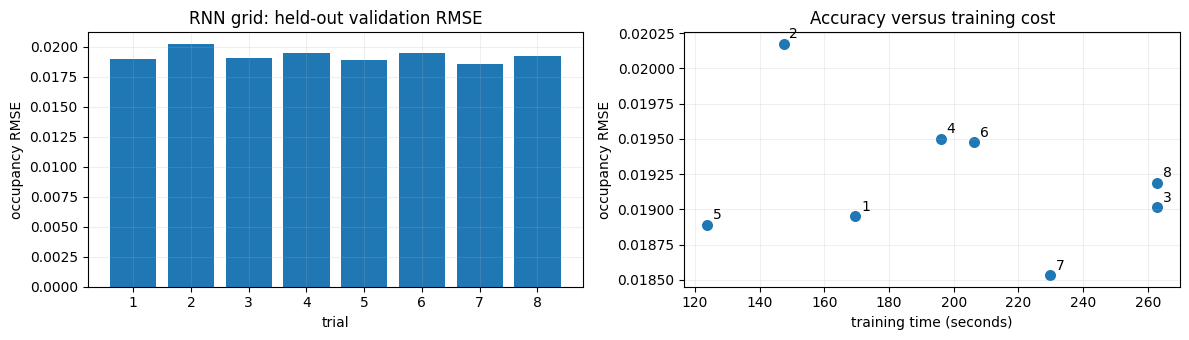

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_trials = rnn_trials_df.sort_values("Trial")
axes[0].bar(plot_trials["Trial"].astype(str), plot_trials["held_val_RMSE"])
axes[0].set(title="RNN grid: held-out validation RMSE", xlabel="trial", ylabel="occupancy RMSE")
axes[1].scatter(plot_trials["Train seconds"], plot_trials["held_val_RMSE"], s=48)
for _, row in plot_trials.iterrows():
    axes[1].annotate(str(int(row["Trial"])), (row["Train seconds"], row["held_val_RMSE"]), xytext=(4,4), textcoords="offset points")
axes[1].set(title="Accuracy versus training cost", xlabel="training time (seconds)", ylabel="occupancy RMSE")
for ax in axes: ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

### 14.3 — Tuned RNN assessment, fair validation comparison, and checkpoint

Compare using the exact held-out-sensor validation window instances already used for Stage 1.

,Model,MAE,RMSE,Params,Train seconds,RMSE improvement vs best baseline (%),Inference seconds,Inference ms/window
0,Global CNN (held-out val),0.008282,0.017472,45793,62.091577,29.677706,NaN,NaN
1,Global MLP (held-out val),0.008546,0.017666,12929,61.370359,28.898110,NaN,NaN
2,Global RNN tuned (held-out val),0.009037,0.018533,4289,229.733986,25.406324,10.516331,0.125906
3,Global RNN (held-out val),0.009284,0.018797,4289,281.073107,24.345694,11.926365,0.142788
4,Persistence (held-out val),0.012639,0.024846,0,0.000000,0.000000,NaN,NaN
5,Weekly seasonal naive (held-out val),0.010564,0.027648,0,0.000000,-11.278115,NaN,NaN


Initial RNN RMSE: 0.018797
Tuned RNN RMSE:   0.018533
RNN tuning improvement (%): 1.4


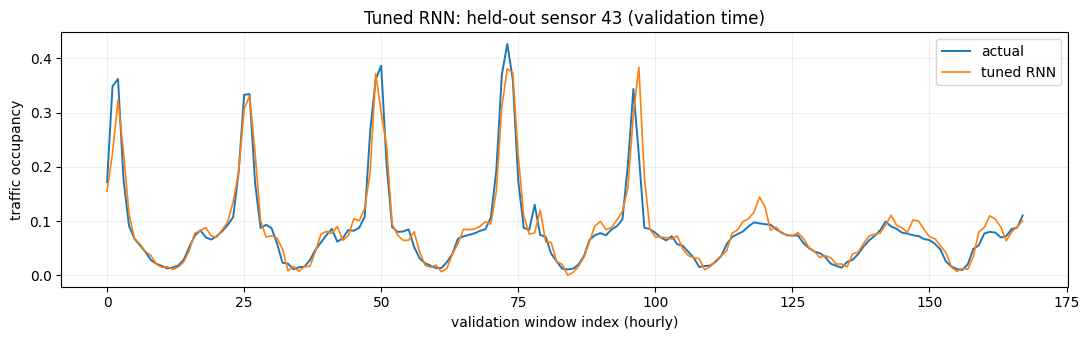

In [ ]:
t0 = perf_counter()
best_rnn_metrics, best_rnn_y_val, best_rnn_y_pred = score_packs(best_rnn, held_packs, split="val", cnn=True)
best_rnn_infer_seconds = perf_counter() - t0
best_row = rnn_trials_df.iloc[0]
best_rnn_metrics.update({
    "Model": "Global RNN tuned (held-out val)",
    "Params": best_rnn.count_params(),
    "Train seconds": float(best_row["Train seconds"]),
    "Inference seconds": best_rnn_infer_seconds,
    "Inference ms/window": 1e3 * best_rnn_infer_seconds / len(best_rnn_y_val),
})

stage2_rnn_comparison = pd.concat([
    comparison.copy(), pd.DataFrame([rnn_held_metrics, best_rnn_metrics])
], ignore_index=True)
stage2_rnn_comparison["RMSE improvement vs best baseline (%)"] = (
    100 * (best_baseline_rmse - stage2_rnn_comparison["RMSE"]) / best_baseline_rmse
)
stage2_rnn_comparison = stage2_rnn_comparison.sort_values("RMSE").reset_index(drop=True)
display(stage2_rnn_comparison)

# Show improvement relative to the initial untuned RNN.
print("Initial RNN RMSE:", round(rnn_held_metrics["RMSE"], 6))
print("Tuned RNN RMSE:  ", round(best_rnn_metrics["RMSE"], 6))
print("RNN tuning improvement (%):", round(
    100*(rnn_held_metrics["RMSE"] - best_rnn_metrics["RMSE"])/rnn_held_metrics["RMSE"], 2))

n_show = min(168, len(example_pack["y_val_raw"]))
tuned_pred_scaled = best_rnn.predict(example_pack["X_val"][..., None], verbose=0).ravel()
tuned_pred = inverse_transform(tuned_pred_scaled, example_pack["mu"], example_pack["sigma"])
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(example_pack["y_val_raw"][:n_show], label="actual", lw=1.4)
ax.plot(tuned_pred[:n_show], label="tuned RNN", lw=1.2)
ax.set(title=f"Tuned RNN: held-out sensor {example_pack['sensor']} (validation time)",
       xlabel="validation window index (hourly)", ylabel="traffic occupancy")
ax.grid(alpha=0.2); ax.legend(); plt.tight_layout(); plt.show()

## 15 — Global LSTM

Same pooled windows as the CNN, shaped `(samples, LOOKBACK, 1)`.

- **LSTM:** walks the window hour by hour and keeps a state, so earlier hours can affect the forecast without a separate lag feature.
- **32 units:** a small memory, in the same size range as the MLP hidden layers.
- **Final state only:** one vector for the whole window, then a linear unit for the next standardized occupancy.
- **Dropout 0:** the default does not drop inputs. Nonzero dropout is in the grid, and it turns off the fast LSTM kernel, so those trials are slower.

Adam, learning rate 0.001, MSE, batch size 64, the 40-epoch cap, patience 5, and the seed match the MLP and CNN. Early stopping still watches train-sensor validation. Units, dropout, and learning rate here are the default cell of the Section 15 grid, not the searched winner.


In [ ]:
def build_lstm_from(config):
    model = Sequential([
        Input(shape=(LOOKBACK, 1)),
        LSTM(config["units"], dropout=config["dropout"]),
        Dense(1),
    ])
    model.compile(optimizer=Adam(config["learning_rate"]), loss="mse")
    return model

default_lstm_config = {"units": 32, "dropout": 0.0, "learning_rate": LR}
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
lstm = build_lstm_from(default_lstm_config)
lstm.summary()

t0 = perf_counter()
lstm_hist = lstm.fit(
    X_train_cnn, y_train,
    validation_data=(X_es_cnn, y_es),
    epochs=EPOCHS,
    batch_size=BATCH,
    shuffle=True,
    callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
    verbose=1,
)
lstm_time = perf_counter() - t0
lstm_default_weights = lstm.get_weights()
print(f"LSTM training time: {lstm_time:.1f}s | epochs run: {len(lstm_hist.history['loss'])}")

# cnn=True only adds the sensor channel. The LSTM uses that same shape.
lstm_held_metrics, _, _ = score_packs(lstm, held_packs, "val", cnn=True)
lstm_held_metrics["Model"] = "Global LSTM (held-out val)"
lstm_held_metrics["Params"] = lstm.count_params()
lstm_held_metrics["Train seconds"] = lstm_time
display(pd.DataFrame([lstm_held_metrics]))


In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(lstm_hist.history["loss"], label="train")
ax.plot(lstm_hist.history["val_loss"], label="val (train sensors)")
ax.set(title="Global LSTM learning curves", xlabel="epoch", ylabel="MSE (scaled space)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### 15.1 — LSTM grid search

Same screening budget and the same held-out RMSE rule as Sections 11 and 16. The winner is retrained on all pooled training windows.

| Parameter | Values | Default in the grid |
|---|---|---|
| Units | 32, 64 | 32 |
| Input dropout | 0.0, 0.2 | 0.0 |
| Learning rate | 0.001, 0.0003 | 0.001 |

That is **8 fits**. Batch size 64, MSE, seed `401003`, and recurrent dropout 0 stay fixed. The Section 15 network is the cell with 32 units, dropout 0, and learning rate 0.001.

Nonzero input dropout turns off the optimized LSTM kernel, so those four cells are slower. An LSTM also steps through all `LOOKBACK` hours of every window, so this is the slow screening block. A GPU is worth using here.


In [ ]:
lstm_space = {
    "units": [32, 64],
    "dropout": [0.0, 0.2],
    "learning_rate": [1e-3, 3e-4],
}
lstm_configs = expand_grid(lstm_space)
print(
    f"LSTM search budget: {len(lstm_configs)} configurations "
    f"on {len(X_grid_seq)} windows, {GRID_EPOCHS} epochs"
)

screen_start = perf_counter()
lstm_grid_results = run_grid(
    "LSTM", lstm_configs, build_lstm_from, X_grid_seq, y_grid_flat, X_es_cnn, y_es, True
)
lstm_screen_seconds = perf_counter() - screen_start

best_lstm_config = lstm_configs[int(lstm_grid_results.iloc[0]["Trial"]) - 1]
lstm_weights, lstm_tuned_metrics = retrain_winner(
    build_lstm_from, best_lstm_config, X_train_cnn, y_train, X_es_cnn, y_es, True,
    "Tuned global LSTM (held-out val)",
)

print("\nLSTM grid (selected row is first):")
display(lstm_grid_results)
print("Selected LSTM:", best_lstm_config)
print(f"LSTM screening wall time: {lstm_screen_seconds:.1f}s. The tuned-row time below is the full retrain.")
display(pd.DataFrame([lstm_tuned_metrics]))


## 16 — Global TCN

A **Temporal Convolutional Network** is the CNN from Section 10 rebuilt so that it (a) never looks at the future and (b) can see the whole week without pooling:

| | Global CNN (Sec. 10) | Global TCN (this section) |
|---|---|---|
| Padding | `same` (looks at future neighbours) | `causal` (output at *t* only sees ≤ *t*) |
| Dilation | none | exponential: 1, b, b², … per residual block |
| Depth | 2 conv layers | residual blocks, each = 2 dilated causal convs + skip connection |
| Down-sampling | `MaxPooling1D(2)` ×2 | none inside the blocks (pooling would undo the dilation); a single *last-timestep* read-out at the end |
| Head | Flatten → Dense(32) → Dropout → Dense(1) | same |
| Activations / optimizer / loss | ReLU, linear output, Adam, MSE | same |

**Receptive field.** With two convs per block, kernel size *k* and dilations *d₁…d_L*:  
`RF = 1 + 2·(k − 1)·Σ dᵢ`  
The number of blocks is **derived** for every pair of [k, dilation base] so that `RF ≥ LOOKBACK` (one week = 168 h). Every configuration in the grid therefore sees the full window; depth is a consequence of kernel size and dilation base rather than a free knob.

**Read-out.** Because the convs are causal, only the *last* time step has seen the entire window, so the head reads that step (`Cropping1D`) instead of flattening 168 steps.

In [ ]:
from itertools import product
import json
from tensorflow.keras import Model
from tensorflow.keras.layers import Add, Activation, Cropping1D

# ---------- Receptive-field helpers ----------
def receptive_field(kernel_size, dilations, convs_per_block=2):
    return 1 + convs_per_block * (kernel_size - 1) * sum(dilations)

def dilations_for_lookback(kernel_size, dilation_base, lookback):
    """Add blocks (dilation = base**i) until the receptive field covers the lookback window."""
    dilations = []
    while receptive_field(kernel_size, dilations) < lookback:
        dilations.append(dilation_base ** len(dilations))
    return dilations

# ---------- Residual block ----------
def residual_block(x, filters, kernel_size, dilation, dropout):
    shortcut = x if x.shape[-1] == filters else Conv1D(filters, 1)(x)  # 1x1 conv when channels differ
    for _ in range(2):
        x = Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation)(x)
        x = tf.keras.layers.LayerNormalization()(x)
        x = Activation("relu")(x)
        x = Dropout(dropout)(x)
    return Activation("relu")(Add()([shortcut, x]))

# ---------- Full model ----------
def build_tcn(lookback, filters, kernel_size, dilation_base, lr, block_dropout=0.1, head_dropout=0.2):
    dilations = dilations_for_lookback(kernel_size, dilation_base, lookback)
    assert receptive_field(kernel_size, dilations) >= lookback, "Receptive field does not cover lookback"

    inp = Input(shape=(lookback, 1))
    x = inp
    for d in dilations:
        x = residual_block(x, filters, kernel_size, d, block_dropout)

    x = Cropping1D(cropping=(lookback - 1, 0))(x)   # keep only the last time step (sees full window)
    x = Flatten()(x)
    x = Dense(32, activation="relu")(x)
    x = Dropout(head_dropout)(x)
    out = Dense(1)(x)                               # linear output

    model = Model(inp, out, name=f"tcn_k{kernel_size}_b{dilation_base}_f{filters}")
    model.compile(optimizer=Adam(lr), loss="mse")
    return model, dilations

# ---------- Data views (same windows as the MLP/CNN; shape = (N, LOOKBACK, 1)) ----------
X_tcn_train = X_train[..., None]
X_es_tcn = X_es[..., None]

# ---------- Sanity check: one default config ----------
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
_demo, _dil = build_tcn(LOOKBACK, filters=16, kernel_size=3, dilation_base=2, lr=LR)
print(f"Dilations: {_dil} | receptive field = {receptive_field(3, _dil)} h (lookback = {LOOKBACK} h)")
_demo.summary()

Dilations: [1, 2, 4, 8, 16, 32] | receptive field = 253 h (lookback = 168 h)


Model: "tcn_k3_b2_f16"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 168, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 168, 16)   │         64 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 168, 16)   │         32 │ conv1d_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 168, 16)   │          0 │ layer_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 168, 16)   │          0 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 168, 16)   │        784 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 168, 16)   │         32 │ conv1d_2[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 168, 16)   │          0 │ layer_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 168, 16)   │         32 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 168, 16)   │          0 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 168, 16)   │          0 │ conv1d[0][0],     │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 168, 16)   │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 168, 16)   │        784 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 168, 16)   │         32 │ conv1d_3[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 168, 16)   │          0 │ layer_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 168, 16)   │          0 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 168, 16)   │        784 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 168, 16)   │         32 │ conv1d_4[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 168, 16)   │          0 │ layer_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 9,681 (37.82 KB)

 Trainable params: 9,681 (37.82 KB)

 Non-trainable params: 0 (0.00 B)

### 16.1 — HPO protocol (fixed *before* looking at results)

| Item | Choice |
|---|---|
| **Method** | Exhaustive grid, 2 values × 4 hyperparameters = **16 trials** |
| **Search space** | dilation base ∈ {2, 3} · filters ∈ {16, 32} · kernel size ∈ {3, 7} · learning rate ∈ {1e-3, 3e-3} |
| **Depth** | Derived per trial so that RF ≥ 168 h (see 16) |
| **Fixed** | Adam, MSE, ReLU hidden / linear output, batch 64, block dropout 0.1, head dropout 0.2, same seed every trial |
| **Trial budget** | ≤ `GRID_EPOCHS` epochs on a fixed random subset of `GRID_MAX_TRAIN` pooled training windows (same subset for all trials) |
| **Stopping rule** | `EarlyStopping(val_loss, patience=GRID_PATIENCE, restore_best_weights=True)` on train-sensor validation windows (same as MLP/CNN) |
| **Objective** | **Held-out-sensor validation RMSE** (original occupancy units). Ties → fewer parameters |
| **Test set** | Not touched |

The winner is then **retrained once** on the full pooled training set with the same `EPOCHS` / `PATIENCE` as the MLP and CNN.

In [ ]:
# ---------------- Search space & budget ----------------
GRID = {
    "dilation_base": [2, 3],
    "filters":       [16, 32],
    "kernel_size":   [3, 7],
    "lr":            [1e-3, 5e-3],
}
GRID_EPOCHS = 15          # per-trial cap (final retrain uses EPOCHS)
GRID_PATIENCE = 3
GRID_MAX_TRAIN = 40_000   # fixed subset of pooled train windows for the search

rng = np.random.default_rng(SEED)
if len(X_tcn_train) > GRID_MAX_TRAIN:
    gidx = rng.choice(len(X_tcn_train), size=GRID_MAX_TRAIN, replace=False)
    X_grid, y_grid = X_tcn_train[gidx], y_train[gidx]
else:
    X_grid, y_grid = X_tcn_train, y_train

def run_trial(cfg, X_tr, y_tr, epochs, patience, verbose=0):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model, dilations = build_tcn(LOOKBACK, **cfg)

    t0 = perf_counter()
    hist = model.fit(
        X_tr, y_tr,
        validation_data=(X_es_tcn, y_es),
        epochs=epochs,
        batch_size=BATCH,
        shuffle=True,
        callbacks=[EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)],
        verbose=verbose,
    )
    train_s = perf_counter() - t0

    t1 = perf_counter()
    m, _, _ = score_packs(model, held_packs, "val", cnn=True)   # cnn=True -> adds the channel axis
    infer_s = perf_counter() - t1
    return model, hist, dilations, m, train_s, infer_s

grid_cfgs = [dict(zip(GRID.keys(), vals)) for vals in product(*GRID.values())]
print(f"Running {len(grid_cfgs)} trials …")

trial_rows = []
for i, cfg in enumerate(grid_cfgs):
    model_i, hist_i, dil_i, m_i, tr_s, inf_s = run_trial(cfg, X_grid, y_grid, GRID_EPOCHS, GRID_PATIENCE)
    trial_rows.append({
        "trial": i,
        **cfg,
        "blocks": len(dil_i),
        "dilations": str(dil_i),
        "RF (h)": receptive_field(cfg["kernel_size"], dil_i),
        "Params": model_i.count_params(),
        "epochs run": len(hist_i.history["loss"]),
        "best val_loss": min(hist_i.history["val_loss"]),
        "MAE": m_i["MAE"],
        "RMSE": m_i["RMSE"],
        "Train seconds": tr_s,
        "Inference seconds": inf_s,
    })
    print(f"[{i+1:2d}/{len(grid_cfgs)}] {cfg} | blocks={len(dil_i)} | RMSE={m_i['RMSE']:.5f} | {tr_s:.0f}s")

hpo_table = pd.DataFrame(trial_rows).sort_values(["RMSE", "Params"]).reset_index(drop=True)
display(hpo_table)

best_trial = int(hpo_table.loc[0, "trial"])
best_cfg = grid_cfgs[best_trial]
print("\nSelected config (lowest held-out val RMSE):", best_cfg)

Running 16 trials …
[ 1/16] {'dilation_base': 2, 'filters': 16, 'kernel_size': 3, 'lr': 0.001} | blocks=6 | RMSE=0.01766 | 155s
[ 2/16] {'dilation_base': 2, 'filters': 16, 'kernel_size': 3, 'lr': 0.005} | blocks=6 | RMSE=0.01760 | 149s
[ 3/16] {'dilation_base': 2, 'filters': 16, 'kernel_size': 7, 'lr': 0.001} | blocks=4 | RMSE=0.01783 | 109s
[ 4/16] {'dilation_base': 2, 'filters': 16, 'kernel_size': 7, 'lr': 0.005} | blocks=4 | RMSE=0.01783 | 88s
[ 5/16] {'dilation_base': 2, 'filters': 32, 'kernel_size': 3, 'lr': 0.001} | blocks=6 | RMSE=0.01726 | 166s
[ 6/16] {'dilation_base': 2, 'filters': 32, 'kernel_size': 3, 'lr': 0.005} | blocks=6 | RMSE=0.01790 | 119s
[ 7/16] {'dilation_base': 2, 'filters': 32, 'kernel_size': 7, 'lr': 0.001} | blocks=4 | RMSE=0.01788 | 137s
[ 8/16] {'dilation_base': 2, 'filters': 32, 'kernel_size': 7, 'lr': 0.005} | blocks=4 | RMSE=0.01771 | 90s
[ 9/16] {'dilation_base': 3, 'filters': 16, 'kernel_size': 3, 'lr': 0.001} | blocks=5 | RMSE=0.01751 | 138s
[10/16] {'

,trial,dilation_base,filters,kernel_size,lr,blocks,dilations,RF (h),Params,epochs run,best val_loss,MAE,RMSE,Train seconds,Inference seconds
0,14,3,32,7,0.001,4,"[1, 3, 9, 27]",481,52321,15,0.139827,0.007400,0.016938,122.497020,17.080085
1,12,3,32,3,0.001,5,"[1, 3, 9, 27, 81]",485,29857,15,0.144687,0.007581,0.017157,153.114392,18.953588
2,10,3,16,7,0.001,4,"[1, 3, 9, 27]",481,13649,14,0.144989,0.007716,0.017190,108.405308,16.435381
3,15,3,32,7,0.005,4,"[1, 3, 9, 27]",481,52321,11,0.147428,0.007959,0.017193,91.793334,13.565922
4,4,2,32,3,0.001,6,"[1, 2, 4, 8, 16, 32]",253,36193,15,0.144321,0.007848,0.017256,165.633749,30.680485
5,11,3,16,7,0.005,4,"[1, 3, 9, 27]",481,13649,11,0.148769,0.008105,0.017345,84.956778,13.004054
6,8,3,16,3,0.001,5,"[1, 3, 9, 27, 81]",485,8049,15,0.150870,0.007820,0.017511,138.140831,18.494228
7,1,2,16,3,0.005,6,"[1, 2, 4, 8, 16, 32]",253,9681,15,0.150383,0.008191,0.017605,149.324423,14.822874
8,0,2,16,3,0.001,6,"[1, 2, 4, 8, 16, 32]",253,9681,15,0.150444,0.008231,0.017656,155.128498,23.761651
9,7,2,32,7,0.005,4,"[1, 2, 4, 8]",181,52321,12,0.154152,0.008005,0.017709,90.291688,13.694587



Selected config (lowest held-out val RMSE): {'dilation_base': 3, 'filters': 32, 'kernel_size': 7, 'lr': 0.001}


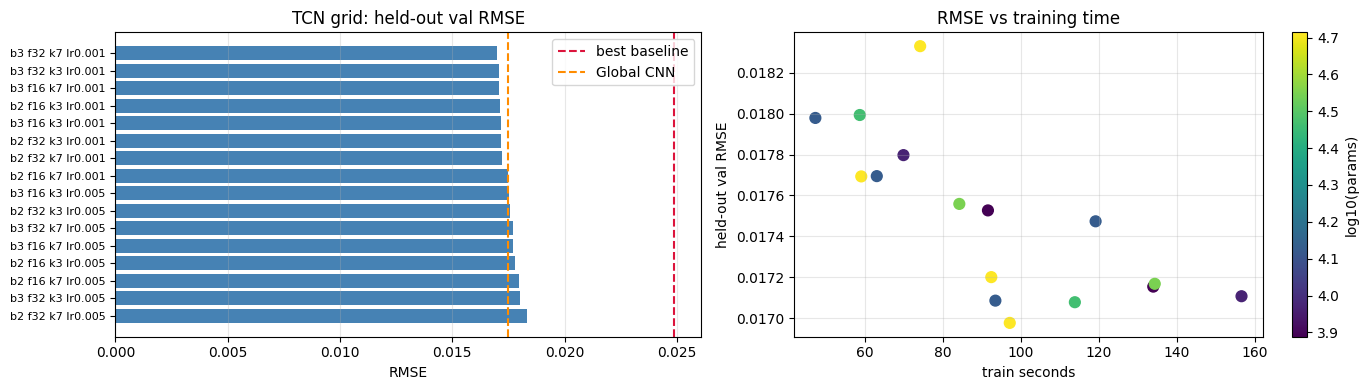

mean RMSE
hyperparameter value            
dilation_base  2.000    0.017577
               3.000    0.017400
filters        16.000   0.017477
               32.000   0.017500
kernel_size    3.000    0.017423
               7.000    0.017554
lr             0.001    0.017155
               0.005    0.017821

In [ ]:
# ---------------- HPO evidence: trials plot + marginal effects ----------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

order = hpo_table.sort_values("RMSE")
labels = [f"b{r.dilation_base} f{r.filters} k{r.kernel_size} lr{r.lr:g}" for r in order.itertuples()]
axes[0].barh(range(len(order)), order["RMSE"], color="steelblue")
axes[0].set_yticks(range(len(order))); axes[0].set_yticklabels(labels, fontsize=8)
axes[0].invert_yaxis()
axes[0].axvline(best_baseline_rmse, color="crimson", ls="--", label="best baseline")
axes[0].axvline(cnn_held_metrics["RMSE"], color="darkorange", ls="--", label="Global CNN")
axes[0].axvline(lstm_held_metrics["RMSE"], color="seagreen", ls="--", label="Global LSTM")
axes[0].set(title="TCN grid: held-out val RMSE", xlabel="RMSE")
axes[0].legend(); axes[0].grid(alpha=0.3, axis="x")

sc = axes[1].scatter(hpo_table["Train seconds"], hpo_table["RMSE"], c=np.log10(hpo_table["Params"]), cmap="viridis", s=60)
axes[1].set(title="RMSE vs training time", xlabel="train seconds", ylabel="held-out val RMSE")
plt.colorbar(sc, ax=axes[1], label="log10(params)")
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Mean RMSE for each value of each hyperparameter (averaged over the other three)
marginals = pd.concat({
    h: hpo_table.groupby(h)["RMSE"].mean() for h in GRID
}, names=["hyperparameter", "value"]).rename("mean RMSE").to_frame()
display(marginals)

### 16.2 — Tuned TCN

Retrain the selected configuration on the **full** pooled training windows with the same `EPOCHS`, `PATIENCE`, `BATCH` and seed as the MLP/CNN. This is the searched winner, not a default model. The defaults are the ones named "Global" in Sections 9, 10, and 14.

Model: "tcn_k7_b3_f32"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 168, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 168, 32)   │        256 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 168, 32)   │          0 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 168, 32)   │      7,200 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 168, 32)   │          0 │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 168, 32)   │         64 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 168, 32)   │          0 │ dropout_1[0][0],  │
│                     │                   │            │ conv1d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 168, 32)   │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 168, 32)   │      7,200 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 168, 32)   │          0 │ conv1d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 168, 32)   │      7,200 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 168, 32)   │          0 │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 168, 32)   │          0 │ dropout_3[0][0],  │
│                     │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 168, 32)   │          0 │ add_1[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 168, 32)   │      7,200 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 168, 32)   │          0 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 168, 32)   │      7,200 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 168, 32)   │          0 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 168, 32)   │          0 │ dropout_5[0][0],  │
│                     │                   │            │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 168, 32)   │          0 │ add_2[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 168, 32)   │      7,200 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 51,809 (202.38 KB)

 Trainable params: 51,809 (202.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 23s 10ms/step - loss: 0.2021 - val_loss: 0.1536
Epoch 2/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.1693 - val_loss: 0.1463
Epoch 3/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.1631 - val_loss: 0.1444
Epoch 4/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.1604 - val_loss: 0.1411
Epoch 5/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.1575 - val_loss: 0.1433
Epoch 6/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.1525 - val_loss: 0.1423
Epoch 7/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.1514 - val_loss: 0.1439
Epoch 8/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.1510 - val_loss: 0.1442
Epoch 9/40
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.1472 - val_loss: 0.1477
TCN training time: 110.5s | epochs run: 9
Config: {'dilation_base': 3, 'filters': 32, 'kernel_size': 7, 'lr': 0.001} | dilations [1, 3, 9, 27] | RF = 481 h


,Model,MAE,RMSE,Params,Train seconds,Inference seconds
0,Global TCN (held-out val),0.007757,0.017025,51809,110.497689,10.915658


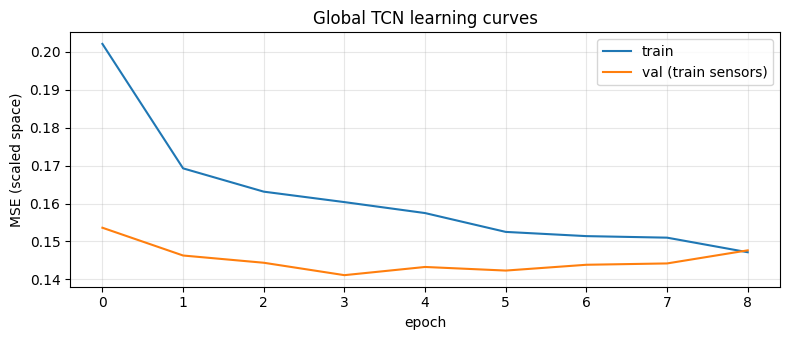

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
tcn, tcn_dil = build_tcn(LOOKBACK, **best_cfg)
tcn.summary()

t0 = perf_counter()
tcn_hist = tcn.fit(
    X_tcn_train, y_train,
    validation_data=(X_es_tcn, y_es),
    epochs=EPOCHS,
    batch_size=BATCH,
    shuffle=True,
    callbacks=[EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)],
    verbose=1,
)
tcn_time = perf_counter() - t0
print(f"TCN training time: {tcn_time:.1f}s | epochs run: {len(tcn_hist.history['loss'])}")

t1 = perf_counter()
tcn_held_metrics, _, _ = score_packs(tcn, held_packs, "val", cnn=True)
tcn_infer = perf_counter() - t1

tcn_held_metrics["Model"] = "Tuned global TCN (held-out val)"
tcn_held_metrics["Params"] = tcn.count_params()
tcn_held_metrics["Train seconds"] = tcn_time
tcn_held_metrics["Inference seconds"] = tcn_infer
print(f"Config: {best_cfg} | dilations {tcn_dil} | RF = {receptive_field(best_cfg['kernel_size'], tcn_dil)} h")
display(pd.DataFrame([tcn_held_metrics]))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(tcn_hist.history["loss"], label="train")
ax.plot(tcn_hist.history["val_loss"], label="val (train sensors)")
ax.set(title="Tuned TCN learning curves", xlabel="epoch", ylabel="MSE (scaled space)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

#### 16.2.1 — Visual comparison on held-out sensors

Actual occupancy against the tuned TCN, CNN, and LSTM, plus the naive baseline with the lowest held-out RMSE. Each network is the held-out-RMSE winner after its full retrain. The slice is one week of the validation period, so the daily shape is visible.

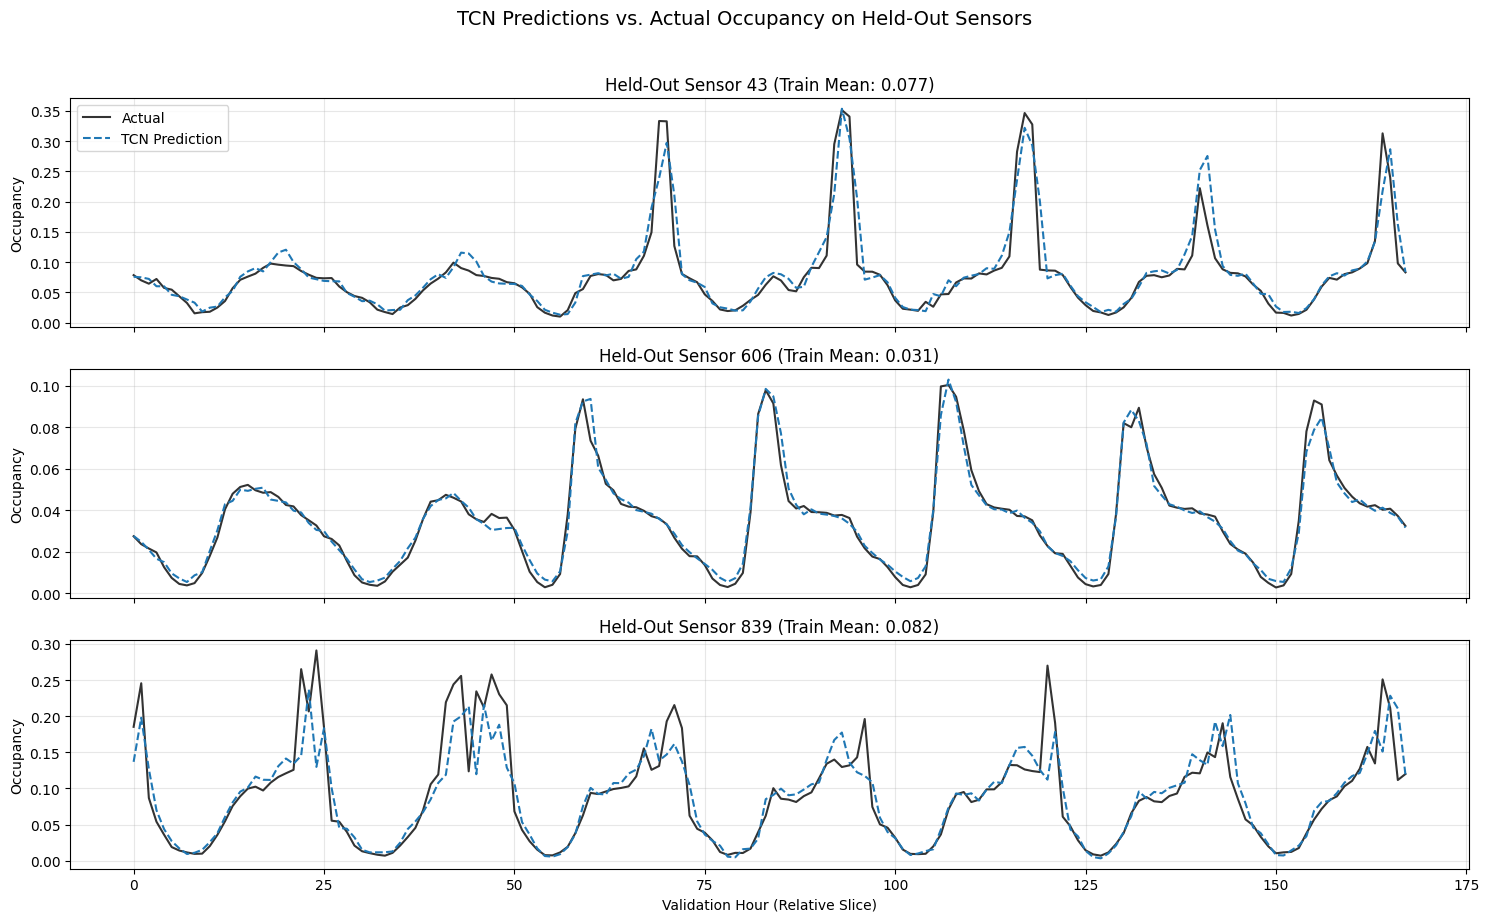

In [ ]:
import matplotlib.pyplot as plt

# Select 3 representative held-out sensors to visualize
sensors_to_plot = [held_out[0], held_out[len(held_out)//2], held_out[-1]]
tuned_cnn = restore_model(build_cnn_from, best_cnn_config, cnn_weights)
tuned_lstm = restore_model(build_lstm_from, best_lstm_config, lstm_weights)
predictors = [
    ("Tuned TCN", tcn, True, "tab:blue"),
    ("Tuned LSTM", tuned_lstm, True, "tab:orange"),
    ("Tuned CNN", tuned_cnn, True, "tab:green"),
]

# The naive with the lowest held-out RMSE. Lag 1, 24, or 168.
best_naive_name = baseline_table.loc[baseline_table["RMSE"].idxmin(), "Model"]
naive_lag = {
    "Persistence (held-out val)": 1,
    "Hourly seasonal naive (held-out val)": 24,
    "Weekly seasonal naive (held-out val)": 168,
}[best_naive_name]
naive_label = best_naive_name.replace(" (held-out val)", "")

fig, axes = plt.subplots(len(sensors_to_plot), 1, figsize=(15, 3.2 * len(sensors_to_plot)), sharex=True)

# One week of the validation period, so the daily shape is visible.
slice_start = 100
slice_end = 268

for idx, s_id in enumerate(sensors_to_plot):
    p = next(pack for pack in held_packs if pack["sensor"] == s_id)
    actual_raw = p["y_val_raw"]
    lag = naive_lag if naive_lag <= p["X_val"].shape[1] else p["X_val"].shape[1]
    naive_raw = inverse_transform(p["X_val"][:, -lag], p["mu"], p["sigma"])
    ax = axes[idx]
    ax.plot(actual_raw[slice_start:slice_end], label="Actual", color="black", alpha=0.85, linewidth=1.5)
    ax.plot(naive_raw[slice_start:slice_end], label=naive_label, color="tab:gray", linestyle=":", linewidth=1.4)
    for name, model, needs_channel, color in predictors:
        Xin = p["X_val"][..., None] if needs_channel else p["X_val"]
        pred_raw = inverse_transform(model.predict(Xin, verbose=0).ravel(), p["mu"], p["sigma"])
        ax.plot(pred_raw[slice_start:slice_end], label=name, color=color, linestyle="--", linewidth=1.2)

    ax.set_title(f"Held-out sensor {s_id} (train mean {p['mu']:.3f})")
    ax.set_ylabel("Occupancy")
    ax.grid(True, alpha=0.3)
    if idx == 0:
        ax.legend(ncol=5, fontsize=8)

axes[-1].set_xlabel("Validation hour (relative slice)")
plt.suptitle("Held-out predictions against actual occupancy", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### 16.3 — Stage 2 comparison, and checkpoint

The table adds the default LSTM, the Section 15 LSTM winner, and the tuned TCN to the Section 12 results. The tuned TCN is the only scored TCN: it is the Section 16.1 winner after the Section 16.2 retrain.

In [ ]:
tcn_held_metrics["Model"] = "Tuned global TCN (held-out val)"
comparison_tcn = pd.concat(
    [
        comparison.drop(columns=["RMSE improvement vs best baseline (%)"]),
        pd.DataFrame([lstm_held_metrics, lstm_tuned_metrics, tcn_held_metrics]),
    ],
    ignore_index=True,
)
comparison_tcn["RMSE improvement vs best baseline (%)"] = (
    100 * (best_baseline_rmse - comparison_tcn["RMSE"]) / best_baseline_rmse
)
display(comparison_tcn.sort_values("RMSE").reset_index(drop=True))

# ---- Checkpoint: model + config + preprocessing state (for the final stage) ----
tcn.save("tcn_best.keras")
ckpt = {
    "model_file": "tcn_best.keras",
    "config": best_cfg,
    "dilations": tcn_dil,
    "receptive_field": receptive_field(best_cfg["kernel_size"], tcn_dil),
    "lookback": LOOKBACK, "horizon": HORIZON, "seed": SEED,
    "batch": BATCH, "epochs_cap": EPOCHS, "patience": PATIENCE,
    "split": {"train_end": int(train_end), "val_end": int(val_end), "n_hours": int(N_HOURS)},
    "scaling": "per_sensor (mu, sigma fit on train hours only)",
    "scalers": {int(p["sensor"]): [p["mu"], p["sigma"]] for p in train_packs + held_packs},
    "held_out_sensors": [int(s) for s in held_out],
    "train_sensors": [int(s) for s in train_sensors],
    "val_metrics_held_out": {k: float(tcn_held_metrics[k]) for k in ("MAE", "RMSE")},
}
with open("tcn_best_config.json", "w") as f:
    json.dump(ckpt, f, indent=2)
print("Saved tcn_best.keras and tcn_best_config.json")

,Model,MAE,RMSE,Params,Train seconds,Inference seconds,RMSE improvement vs best baseline (%)
0,Global TCN (held-out val),0.007757,0.017025,51809,110.497689,10.915658,31.475474
1,Global CNN (held-out val),0.008282,0.017472,45793,68.165998,NaN,29.677706
2,Global MLP (held-out val),0.008546,0.017666,12929,61.908806,NaN,28.898110
3,Persistence (held-out val),0.012639,0.024846,0,0.000000,NaN,0.000000
4,Weekly seasonal naive (held-out val),0.010564,0.027648,0,0.000000,NaN,-11.278115


Saved tcn_best.keras and tcn_best_config.json
